# Predicting Neighbour-Cell Impact of Mobile Network Outages

**Prediction objective.** When a cell goes down, predict each neighbouring cell's **latency, utilization and packet loss** at the first observation during the outage, using only information available before the outage.

**Why this target.** The proposal's original objective was to predict whether a cell will have a new outage in the next 12 hours. This notebook first re-checks that target (section 6) and finds almost no early-warning signal in the KPIs. It then shows (section 7) that outages have a large, measurable impact on neighbouring cells, and that the impact grows with how much displaced load each neighbour has to absorb. That is a predictable, operationally useful target, so it becomes the prediction objective.

**Data splits (presentation slide 9).**

| Split | Train | Validation (tuning) | Test |
|---|---|---|---|
| **A: chronological** (development sites, 80%) | outages starting Jan–Apr | May | June |
| **B: unseen sites** (20% of sites, never used for training or validation) | – | – | June (new sites, future period); also all months (new sites only) |

**Lookback.** The neighbour's KPIs are described with the proposal's 6-hour lookback: the current (last pre-outage) observation, lag-1 (3 h earlier), lag-2 (6 h earlier), mean of lag-1 and lag-2, and trend2 (current − lag-2). Static attributes (technology, region, district) are **not** model inputs; they are used only to slice the results.

**Outline.**
1. Configuration
2. Master table and neighbour relationships
3. Reading all monthly files into a cell × time grid
4. Data quality and network performance EDA
5. Outage events
6. Justification 1: the original target has almost no signal
7. Justification 2: outages measurably affect neighbours
8. Target definition and the modelling dataset
9. Splits A and B
10. Feature sets
11. Evaluation helpers
12. Baselines and tuned models
13. Results with confidence intervals
14. Feature ablation
15. Sanity checks: shuffled target, overfitting, learning curve, stability over months (15b: rolling time-series cross-validation)
16. Error analysis
17. Interpretation
18. Operational views: degraded-neighbour flag and prediction intervals
19. Export for deployment
20. Key observations

## 1. Configuration

In [ ]:
from pathlib import Path
import json, warnings, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (mean_absolute_error, r2_score, average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)
import os
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220, "display.max_columns", 60)

RANDOM_STATE = 42
DATA_DIR = Path(os.environ.get("TELECOM_DATA_DIR", r"C:\Users\Admin\mobile-network-project\Data"))
MASTER_PATH = DATA_DIR / "Dataset_1_Cell_Information.csv"
MONTH_FILES = [DATA_DIR / f"2025_{m:02d}.csv" for m in range(1, 7)]
OUTPUT_DIR  = DATA_DIR / "impact_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Time grid: KPIs every 3 hours on 00:00, 03:00, ..., 21:00
GRID_STEP_H = 3
GRID_START  = pd.Timestamp("2025-01-01 00:00:00")
GRID_END    = pd.Timestamp("2025-06-30 21:00:00")
LOOKBACK_STEPS = 2                       # 6-hour lookback

# Split A (chronological) and split B (unseen sites)
TRAIN_END = pd.Timestamp("2025-04-30 23:59:59")   # Jan-Apr train
VALID_END = pd.Timestamp("2025-05-31 23:59:59")   # May validation, June test
UNSEEN_SITE_FRACTION = 0.20

# Prediction targets and neighbours
IMPACT_TARGETS   = ["Latency", "Utilization", "Packet_Loss"]
NEIGHBOUR_SOURCE = "listed+site"   # "listed" = Neighbor_Cell_ID only, "site" = same-site cells only, "listed+site" = both
CONTROL_WEEKS    = [-2, -1, 1, 2]  # matched normal periods for the impact analysis (section 7 only)
DEGRADED_REL_INCREASE = 0.20       # "degraded neighbour" = KPI rises by more than 20% vs. its pre-outage value

# Justification 1 (original target)
SIGNAL_HORIZONS_H = [3, 6, 12]
SIGNAL_NEG_SAMPLE = 400_000

INCLUDE_BOOSTING = True            # gradient boosting is listed on slide 9
FAST_MODE        = False           # smaller grids for a quick test run
N_BOOT           = 500             # bootstrap resamples (resampling outages)

CHUNK_SIZE = 1_000_000
USE_CACHE  = True                  # the first run writes a ~1.4 GB cache so later runs skip the CSV pass
CACHE_PATH = OUTPUT_DIR / "kpi_grid_cache.npz"

print("Python", sys.version.split()[0], "| pandas", pd.__version__)
print("Master exists:", MASTER_PATH.exists(), "| monthly files:", [p.name for p in MONTH_FILES if p.exists()])

Python 3.13.15 | pandas 2.3.3
Master exists: True | monthly files: ['2025_01.csv', '2025_02.csv', '2025_03.csv', '2025_04.csv', '2025_05.csv', '2025_06.csv']


## 2. Master table and neighbour relationships

In [2]:
master = pd.read_csv(MASTER_PATH, low_memory=False)
need = {"Site_ID", "Cell_ID", "Technology", "Region", "District", "Neighbor_Cell_ID"}
if need - set(master.columns):
    raise ValueError(f"Missing master columns: {need - set(master.columns)}")
for c in ["Site_ID", "Cell_ID"]:
    master[c] = master[c].astype(str).str.strip()
print("Master rows:", len(master), "| sites:", master.Site_ID.nunique(), "| cells:", master.Cell_ID.nunique(),
      "| duplicate Cell_ID rows:", int(master.Cell_ID.duplicated().sum()))
master = master.drop_duplicates("Cell_ID").reset_index(drop=True)

CELLS = master["Cell_ID"].to_numpy()
cell_to_idx = {c: i for i, c in enumerate(CELLS)}
N_CELLS = len(CELLS)
site_codes, SITES = pd.factorize(master["Site_ID"])
site_of_cell = site_codes.astype(np.int32)

rows, cols, unknown_nbr = [], [], 0
for i, raw in enumerate(master["Neighbor_Cell_ID"].fillna("").astype(str)):
    for n in raw.replace(";", ",").split(","):
        n = n.strip()
        if not n or n == CELLS[i]:
            continue
        j = cell_to_idx.get(n)
        if j is None: unknown_nbr += 1
        else: rows.append(i); cols.append(j)
A_NBR = sparse.csr_matrix((np.ones(len(rows), np.float32), (rows, cols)), shape=(N_CELLS, N_CELLS)); A_NBR.data[:] = 1
ss = pd.DataFrame({"i": np.arange(N_CELLS), "s": site_of_cell}); pr = ss.merge(ss, on="s"); pr = pr[pr.i_x != pr.i_y]
A_SITE = sparse.csr_matrix((np.ones(len(pr), np.float32), (pr.i_x, pr.i_y)), shape=(N_CELLS, N_CELLS))
A_ANY = ((A_NBR + A_SITE) > 0).astype(np.float32).tocsr()
A_USE = {"listed": A_NBR, "site": A_SITE, "listed+site": A_ANY}[NEIGHBOUR_SOURCE].tocsr()

deg = np.asarray(A_NBR.sum(1)).ravel()
same_site_listed = A_NBR.multiply(A_SITE).sum()
print(f"Listed neighbour links: {A_NBR.nnz:,} (unknown IDs {unknown_nbr:,}) | per cell median {np.median(deg):.0f}, "
      f"max {deg.max():.0f}, cells with none {(deg == 0).sum():,}")
print(f"Listed links that are on the same site: {100 * same_site_listed / max(A_NBR.nnz, 1):.1f}% | "
      f"same-site links: {A_SITE.nnz:,} | neighbour set used ({NEIGHBOUR_SOURCE}): {A_USE.nnz:,} links")
display(master.groupby("Technology").size().rename("cells").to_frame().T)

Master rows: 22900 | sites: 6000 | cells: 22900 | duplicate Cell_ID rows: 0
Listed neighbour links: 235,528 (unknown IDs 0) | per cell median 11, max 12, cells with none 0
Listed links that are on the same site: 20.0% | same-site links: 65,400 | neighbour set used (listed+site): 253,706 links


Technology,2G,3G,4G,5G
cells,6000,6000,6000,4900


## 3. Read all monthly files into a cell × time grid

Midnight timestamps are sometimes stored as a bare date (`2025-02-01`). `parse_ts` restores the missing `00:00:00` before strict parsing, so those rows are no longer lost. Each KPI is stored at `[cell, time slot]`. Lags are therefore exactly 3 h and 6 h back, and a missing observation becomes a missing value instead of a shifted lag.

In [3]:
EXPECTED = ["Timestamp","Site_ID","Cell_ID","Record_Type","Status","Traffic","Connected_Users","Throughput",
            "Latency","Packet_Loss","Load","Capacity","Alarm_Count","Previous_Outage_Count",
            "Cell_Down_Time","Cell_Up_Time"]
RAW8 = ["Traffic","Connected_Users","Throughput","Latency","Packet_Loss","Alarm_Count","Load","Capacity"]
STEP = pd.Timedelta(hours=GRID_STEP_H)
N_T = int((GRID_END - GRID_START) / STEP) + 1
GRID_TIMES = pd.date_range(GRID_START, periods=N_T, freq=f"{GRID_STEP_H}h")

def parse_ts(s):
    s = s.astype("string").str.strip()
    s = s.where(s.str.len() != 10, s + " 00:00:00")
    return pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S", errors="coerce")

def read_all():
    G = {v: np.full((N_CELLS, N_T), np.nan, np.float32) for v in RAW8}
    G_prev = np.full((N_CELLS, N_T), -1, np.int16)
    has_kpi = np.zeros((N_CELLS, N_T), bool)
    ev_parts, dq = [], {}
    def bump(k, v): dq[k] = dq.get(k, 0) + int(v)
    for path in MONTH_FILES:
        if not path.exists():
            print("Missing:", path); continue
        t0 = time.time()
        for ch in pd.read_csv(path, usecols=lambda c: c in EXPECTED, chunksize=CHUNK_SIZE,
                              dtype={"Site_ID": str, "Cell_ID": str, "Record_Type": str, "Status": str,
                                     "Timestamp": str, "Cell_Down_Time": str, "Cell_Up_Time": str}):
            rt = ch["Record_Type"].str.upper().str.strip()
            for k, v in rt.value_counts().items(): bump(f"{path.name}:{k}", v)
            ts = parse_ts(ch["Timestamp"])
            bump("timestamp_unparseable", ts.isna().sum())
            ev = ch[rt.isin(["OUTAGE", "RECOVERY"])].copy()
            if len(ev):
                ev["Record_Type"] = rt[ev.index]; ev["Timestamp"] = ts[ev.index]
                ev["Cell_Down_Time"] = parse_ts(ev["Cell_Down_Time"]); ev["Cell_Up_Time"] = parse_ts(ev["Cell_Up_Time"])
                ev_parts.append(ev[["Cell_ID","Site_ID","Record_Type","Timestamp","Cell_Down_Time","Cell_Up_Time"]])
            k = rt.eq("KPI") & ts.notna()
            kp = ch[k]; tk = ts[k]
            bump("kpi_status_down", kp["Status"].astype(str).str.upper().eq("DOWN").sum())
            ci = kp["Cell_ID"].str.strip().map(cell_to_idx)
            off = (tk - GRID_START) / STEP
            j = np.floor(off).astype("Int64")
            ok = (ci.notna() & (off == j) & (j >= 0) & (j < N_T)).fillna(False).astype(bool)
            bump("kpi_unknown_cell", ci.isna().sum())
            bump("kpi_off_grid_or_out_of_range", (ci.notna() & ~ok).sum())
            ci = ci[ok].to_numpy(np.int64); j = j[ok].to_numpy(np.int64); kp = kp[ok.to_numpy()]
            bump("kpi_duplicate_cell_time", has_kpi[ci, j].sum())
            has_kpi[ci, j] = True
            for v in RAW8:
                G[v][ci, j] = pd.to_numeric(kp[v], errors="coerce").to_numpy(np.float32)
            G_prev[ci, j] = pd.to_numeric(kp["Previous_Outage_Count"], errors="coerce").fillna(-1).to_numpy(np.int16)
        print(f"{path.name}: read in {time.time()-t0:.0f}s")
    return G, G_prev, has_kpi, pd.concat(ev_parts, ignore_index=True), dq

if USE_CACHE and CACHE_PATH.exists():
    z = np.load(CACHE_PATH, allow_pickle=False)
    G = {v: z[v] for v in RAW8}; G_prev = z["prev"]; has_kpi = z["has_kpi"]
    events = pd.read_pickle(CACHE_PATH.with_suffix(".events.pkl"))
    dq = json.loads(CACHE_PATH.with_suffix(".dq.json").read_text())
    print("Loaded grid from cache:", CACHE_PATH)
else:
    G, G_prev, has_kpi, events, dq = read_all()
    if USE_CACHE:
        np.savez(CACHE_PATH, prev=G_prev, has_kpi=has_kpi, **G)
        events.to_pickle(CACHE_PATH.with_suffix(".events.pkl"))
        CACHE_PATH.with_suffix(".dq.json").write_text(json.dumps(dq))

cap = G["Capacity"]
G["Utilization"] = np.where(cap > 0, 100 * G["Load"] / np.where(cap > 0, cap, 1), np.nan).astype(np.float32)
G["Previous_Outage_Count"] = np.where(G_prev >= 0, G_prev, np.nan).astype(np.float32); del G_prev
VARS9 = ["Traffic","Connected_Users","Throughput","Latency","Packet_Loss","Alarm_Count","Load","Capacity","Utilization"]
print(f"Grid: {N_CELLS:,} cells x {N_T:,} slots | KPI observations: {has_kpi.sum():,}")
display(pd.Series(dq, name="count").to_frame())

Loaded grid from cache: D:\AIT Aug26\ML\Project\Data\impact_outputs\kpi_grid_cache.npz
Grid: 22,900 cells x 1,448 slots | KPI observations: 33,154,563


,count
2025_01.csv:KPI,5678402
2025_01.csv:RECOVERY,1075
2025_01.csv:OUTAGE,1076
timestamp_unparseable,0
kpi_status_down,0
kpi_unknown_cell,0
kpi_off_grid_or_out_of_range,0
kpi_duplicate_cell_time,0
2025_02.csv:KPI,5128851
2025_02.csv:RECOVERY,962


## 4. Data quality and network performance EDA

,missing_%,negative_%,p1,median,p99,max
variable,,,,,,
Traffic,0.0,0.0,0.458000,6.147000,74.744003,133.322006
Connected_Users,0.0,0.0,16.000000,81.000000,371.000000,597.000000
Throughput,0.0,0.0,0.131000,4.563000,134.378998,331.347992
Latency,0.0,0.0,18.155001,76.057999,163.688995,715.331970
Packet_Loss,0.0,0.0,0.128000,0.878000,2.614000,4.322000
Alarm_Count,0.0,0.0,0.000000,0.000000,1.000000,9.000000
Load,0.0,0.0,6.626000,49.505001,869.168030,1788.909058
Capacity,0.0,0.0,12.520000,66.474998,387.976013,399.992004
Utilization,0.0,0.0,44.763000,78.737000,276.131012,1281.510010


Utilization > 100%: 35.5% of observations (Load can exceed Capacity; treat utilization as a relative index, not a strict percentage)
Cells whose Capacity never changes: 100.0%
Observation coverage by hour of day (% of cells): {0: 99.98, 3: 99.99, 6: 99.99, 9: 99.99, 12: 99.99, 15: 99.98, 18: 99.98, 21: 99.98}
Mean KPI by technology


,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Utilization
Technology,,,,,,
2G,1.630000,51.389999,0.430000,120.620003,0.85,58.759998
3G,4.220000,68.290001,2.660000,77.589996,0.60,68.959999
4G,15.950000,135.929993,29.410000,65.879997,1.05,112.680000
5G,36.619999,186.830002,64.360001,47.830002,1.61,169.289993


Mean KPI by region


,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Utilization
Region,,,,,,
Central,13.56,106.139999,22.209999,78.800003,1.00,99.000000
Eastern,13.32,107.580002,22.209999,79.639999,1.00,98.940002
Northern,13.74,107.239998,22.840000,79.300003,1.00,99.680000
Western,13.60,106.629997,21.889999,79.849998,1.01,99.230003


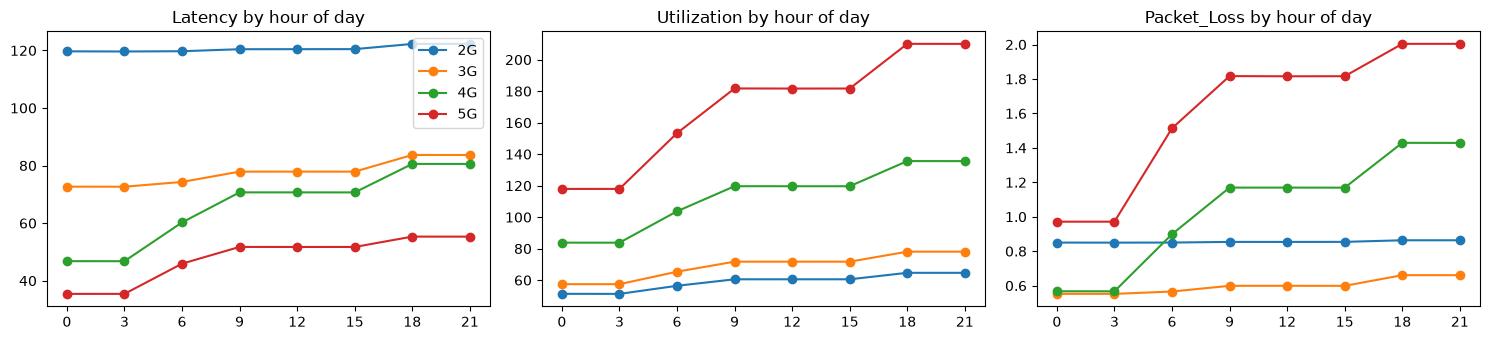

Network-wide monthly mean


,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Utilization
1,13.83,109.190002,22.010000,79.919998,1.01,100.449997
2,13.17,103.989998,22.620001,78.760002,0.98,97.580002
3,13.17,104.000000,22.620001,78.750000,0.98,97.570000
4,13.17,103.989998,22.620001,78.760002,0.98,97.570000
5,13.17,103.989998,22.620001,78.769997,0.98,97.570000
6,14.75,116.470001,21.240000,81.570000,1.06,104.480003


In [4]:
obs = has_kpi
rows = []
for v in VARS9:
    x = G[v][obs]
    rows.append({"variable": v, "missing_%": 100 * np.isnan(x).mean(), "negative_%": 100 * (x < 0).mean(),
                 "p1": np.nanpercentile(x, 1), "median": np.nanmedian(x), "p99": np.nanpercentile(x, 99), "max": np.nanmax(x)})
display(pd.DataFrame(rows).set_index("variable").round(3))
print(f"Utilization > 100%: {100 * np.nanmean(G['Utilization'][obs] > 100):.1f}% of observations "
      "(Load can exceed Capacity; treat utilization as a relative index, not a strict percentage)")
cap_m = np.where(obs, G["Capacity"], np.nan)
cap_rng = np.nanmax(cap_m, axis=1) - np.nanmin(cap_m, axis=1); del cap_m
print(f"Cells whose Capacity never changes: {100 * np.mean(cap_rng[~np.isnan(cap_rng)] == 0):.1f}%")
hours = GRID_TIMES.hour
print("Observation coverage by hour of day (% of cells):",
      pd.Series(obs.mean(0)).groupby(hours).mean().mul(100).round(2).to_dict())

EDA_VARS = ["Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss", "Utilization"]
masked = {v: np.where(obs, G[v], np.nan) for v in EDA_VARS}
cm = pd.DataFrame({v: np.nanmean(masked[v], axis=1) for v in EDA_VARS})
cm[["Technology", "Region"]] = master[["Technology", "Region"]].to_numpy()
print("Mean KPI by technology"); display(cm.groupby("Technology")[EDA_VARS].mean().round(2))
print("Mean KPI by region"); display(cm.groupby("Region")[EDA_VARS].mean().round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, v in zip(axes, ["Latency", "Utilization", "Packet_Loss"]):
    for tech, idx in master.groupby("Technology").indices.items():
        prof = pd.Series(np.nanmean(masked[v][idx], axis=0)).groupby(hours).mean()
        ax.plot(prof.index, prof.values, marker="o", label=tech)
    ax.set_title(f"{v} by hour of day"); ax.set_xticks(range(0, 24, 3))
axes[0].legend(); plt.tight_layout(); plt.show()
print("Network-wide monthly mean")
display(pd.DataFrame({v: pd.Series(np.nanmean(masked[v], axis=0)).groupby(GRID_TIMES.month).mean() for v in EDA_VARS}).round(2))
del masked

## 5. Outage events

Outage start = `Cell_Down_Time`; recovery = the first `Cell_Up_Time` after it. A cell is *down* at slot *t* if an outage started at or before *t* and had not recovered by *t*.

Event rows: 12483 | unknown cells: 0
Outages: 6,243 | with recovery: 6,233 | cells with >=1 outage: 5,489


,count,mean,std,min,10%,25%,50%,75%,90%,max
duration_h,6233.0,2.24,1.02,0.5,0.85,1.37,2.22,3.13,3.67,4.0


Outages per month: {1: 1076, 2: 966, 3: 1016, 4: 943, 5: 1097, 6: 1145}
Outage rate per 1,000 cells by technology: {'2G': 288.8, '3G': 278.0, '4G': 276.0, '5G': 242.0}
Outage rate per 1,000 cells by region: {'Central': 268.3, 'Eastern': 278.4, 'Northern': 270.0, 'Western': 272.4}
Outages per cell (cells with any): {1: 4806, 2: 620, 3: 55, 4: 8}
Outages starting while another cell on the same site is already down: 0.82%


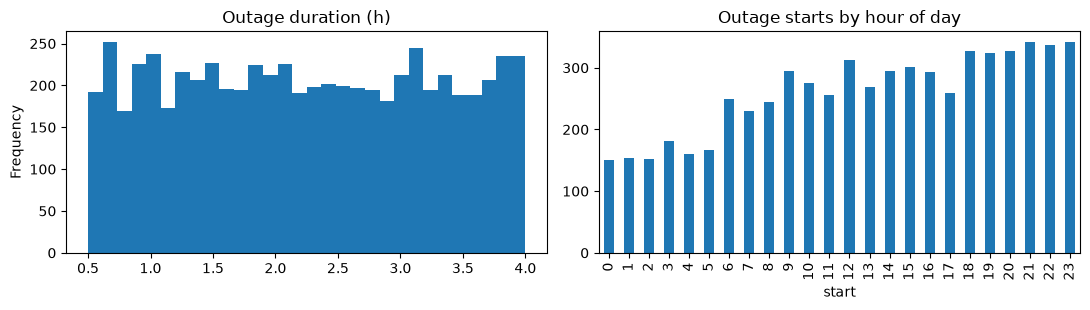

In [5]:
events["Cell_ID"] = events["Cell_ID"].str.strip()
events["ci"] = events["Cell_ID"].map(cell_to_idx)
print("Event rows:", len(events), "| unknown cells:", int(events.ci.isna().sum()))
events = events.dropna(subset=["ci"]).astype({"ci": int})
out = events[events.Record_Type.eq("OUTAGE")].copy()
out["start"] = out["Cell_Down_Time"].fillna(out["Timestamp"])
out = out.dropna(subset=["start"]).drop_duplicates(["ci", "start"]).sort_values("start")
rec = events[events.Record_Type.eq("RECOVERY")].copy()
rec["up"] = rec["Cell_Up_Time"].fillna(rec["Timestamp"])
rec = rec.dropna(subset=["up"]).drop_duplicates(["ci", "up"]).sort_values("up")
out = pd.merge_asof(out, rec[["ci", "up"]], left_on="start", right_on="up", by="ci", direction="forward")
out = out.sort_values(["ci", "start"]).reset_index(drop=True)
nxt = out.groupby("ci")["start"].shift(-1)
out.loc[nxt.notna() & out.up.notna() & (out.up > nxt), "up"] = pd.NaT
out["duration_h"] = (out.up - out.start).dt.total_seconds() / 3600
out["event_id"] = np.arange(len(out))
out["site"] = site_of_cell[out.ci.to_numpy()]

def slot_ceil(ts):
    return np.ceil(((pd.Series(ts) - GRID_START) / STEP).to_numpy(float)).astype(int)
s_slot = slot_ceil(out.start)
u_slot = slot_ceil(out.up.fillna(out.start)); has_up = out.up.notna().to_numpy()
down = np.zeros((N_CELLS, N_T), bool)
for ci, s0, u0, hu in zip(out.ci.to_numpy(), s_slot, u_slot, has_up):
    a = max(s0, 0)
    if a >= N_T: continue
    if not hu:
        later = np.nonzero(has_kpi[ci, a:])[0]; u0 = a + (later[0] if len(later) else N_T - a)
    down[ci, a:min(max(u0, a), N_T)] = True

out_by_site = {}
for r in out.itertuples():
    out_by_site.setdefault(r.site, []).append((r.ci, r.start, r.up))
def site_cells_down_at(c, t):
    """Other cells on c's site whose outage started at or before t and had not recovered by t."""
    return sum(1 for (k, s0, u0) in out_by_site.get(site_of_cell[c], []) if k != c and s0 <= t and (pd.isna(u0) or u0 > t))

out["Technology"] = master.Technology.to_numpy()[out.ci]; out["Region"] = master.Region.to_numpy()[out.ci]
print(f"Outages: {len(out):,} | with recovery: {has_up.sum():,} | cells with >=1 outage: {out.ci.nunique():,}")
display(out.duration_h.describe(percentiles=[.1, .25, .5, .75, .9]).round(2).to_frame("duration_h").T)
print("Outages per month:", out.start.dt.month.value_counts().sort_index().to_dict())
print("Outage rate per 1,000 cells by technology:",
      (1000 * out.groupby("Technology").size() / master.groupby("Technology").size()).round(1).to_dict())
print("Outage rate per 1,000 cells by region:",
      (1000 * out.groupby("Region").size() / master.groupby("Region").size()).round(1).to_dict())
print("Outages per cell (cells with any):", out.groupby("ci").size().value_counts().sort_index().to_dict())
out["site_others_down_at_start"] = [site_cells_down_at(c, t) for c, t in zip(out.ci, out.start)]
print(f"Outages starting while another cell on the same site is already down: "
      f"{100 * (out.site_others_down_at_start > 0).mean():.2f}%")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
out.duration_h.plot.hist(bins=30, ax=axes[0], title="Outage duration (h)")
out.start.dt.hour.value_counts().sort_index().plot.bar(ax=axes[1], title="Outage starts by hour of day")
plt.tight_layout(); plt.show()

## 6. Justification 1: the original target has almost no signal

The original target, *a new outage within the next H hours*, is checked in two ways:
1. **Standardized mean differences (SMD)** between rows shortly before an outage and all other eligible rows. |SMD| < 0.1 means the groups are practically indistinguishable.
2. **A quick Random Forest**, trained on Jan–Apr and scored on June, for horizons of 3, 6 and 12 h. Negatives are subsampled, and the June evaluation re-weights them back to their true frequency. **Lift** = PR-AUC ÷ prevalence, where 1.0 is random.

The full analysis of this target is in the earlier notebook. This section only shows why the prediction objective was changed.

In [6]:
last_obs = int(np.where(has_kpi.any(0))[0].max())
elig = has_kpi & ~down
elig[:, :LOOKBACK_STEPS] = False
elig[:, LOOKBACK_STEPS:] &= has_kpi[:, 1:-1] & has_kpi[:, :-2]
rng = np.random.default_rng(RANDOM_STATE)

def kpi_block(ci, j, prefix=""):
    """9 current values + lag-1, lag-2, mean of the two, trend2 (6-hour lookback) at slot j."""
    d = {}
    for v in VARS9:
        g = G[v]; cur, l1, l2 = g[ci, j], g[ci, j - 1], g[ci, j - 2]
        d[f"{prefix}{v}"] = cur; d[f"{prefix}{v}_lag1"] = l1; d[f"{prefix}{v}_lag2"] = l2
        d[f"{prefix}{v}_mean2"] = (l1 + l2) / 2; d[f"{prefix}{v}_trend2"] = cur - l2
    return pd.DataFrame(d)

signal_rows, smd_tables = [], {}
for H in SIGNAL_HORIZONS_H:
    ok_win = np.zeros(N_T, bool); ok_win[: max(0, last_obs - H // GRID_STEP_H + 1)] = True
    el = elig & ok_win[None, :]
    pos = np.zeros((N_CELLS, N_T), bool)
    for r, s0 in zip(out.itertuples(), s_slot):
        lo = slot_ceil([r.start - pd.Timedelta(hours=H)])[0]
        lo, hi = max(lo, 0), min(s0, N_T)
        if hi > lo: pos[r.ci, lo:hi] = True
    p_idx = np.flatnonzero(el & pos); n_all = np.flatnonzero(el & ~pos)
    n_idx = rng.choice(n_all, size=min(SIGNAL_NEG_SAMPLE, len(n_all)), replace=False)
    idx = np.r_[p_idx, n_idx]; y = np.r_[np.ones(len(p_idx)), np.zeros(len(n_idx))].astype(int)
    ci, j = np.unravel_index(idx, (N_CELLS, N_T))
    X = kpi_block(ci, j); X["Previous_Outage_Count"] = G["Previous_Outage_Count"][ci, j]
    tt = GRID_TIMES[j]
    # 1. SMD
    sd = X.std()
    smd_tables[H] = ((X[y == 1].mean() - X[y == 0].mean()) / sd).rename(f"SMD_{H}h")
    # 2. quick model, June weighted back to the natural prevalence
    tr, te = np.asarray(tt <= TRAIN_END), np.asarray(tt > VALID_END)
    n_june_total = int(((el & ~pos)[:, np.asarray(GRID_TIMES > VALID_END)]).sum())
    w = np.where(y == 1, 1.0, n_june_total / max(((y == 0) & te).sum(), 1))
    rf = RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=50, max_features="sqrt",
                                n_jobs=-1, random_state=RANDOM_STATE).fit(X[tr].fillna(X[tr].median()), y[tr])
    p = rf.predict_proba(X[te].fillna(X[tr].median()))[:, 1]
    prev = (y[te] * w[te]).sum() / w[te].sum()
    ap = average_precision_score(y[te], p, sample_weight=w[te])
    signal_rows.append({"horizon_h": H, "positive_rows": len(p_idx), "prevalence_%": 100 * prev,
                        "June_PR_AUC": ap, "lift_over_random": ap / prev,
                        "June_ROC_AUC": roc_auc_score(y[te], p, sample_weight=w[te]),
                        "max_|SMD|": smd_tables[H].abs().max()})
    del pos, el
signal_df = pd.DataFrame(signal_rows)
display(signal_df.round(5))
smd = pd.concat(smd_tables.values(), axis=1)
print("Largest |SMD| at the 12 h horizon (|SMD| < 0.1 = negligible):")
display(smd.reindex(smd[f"SMD_{SIGNAL_HORIZONS_H[-1]}h"].abs().sort_values(ascending=False).index).head(10).round(3))
signal_df.to_csv(OUTPUT_DIR / "justification_original_target.csv", index=False)

,horizon_h,positive_rows,prevalence_%,June_PR_AUC,lift_over_random,June_ROC_AUC,max_|SMD|
0,3,6229,0.02084,0.00024,1.14329,0.55214,0.14717
1,6,12448,0.04170,0.00047,1.11747,0.54095,0.11457
2,12,24860,0.08358,0.00086,1.03211,0.50957,0.07093


Largest |SMD| at the 12 h horizon (|SMD| < 0.1 = negligible):


,SMD_3h,SMD_6h,SMD_12h
Connected_Users_lag2,-0.074,-0.076,-0.071
Utilization_lag2,-0.074,-0.074,-0.070
Connected_Users_mean2,-0.049,-0.064,-0.067
Utilization_mean2,-0.053,-0.064,-0.067
Load_lag2,-0.064,-0.065,-0.062
Load_mean2,-0.056,-0.060,-0.061
Connected_Users_lag1,-0.020,-0.047,-0.060
Utilization_lag1,-0.029,-0.051,-0.059
Traffic_lag2,-0.063,-0.062,-0.058
Load_lag1,-0.047,-0.055,-0.058


## 7. Justification 2: outages measurably affect neighbours

For every outage and every neighbour that was up just before it, this section compares:
* **Event change:** the neighbour's KPI at the first observation after the outage starts, minus its value at the observation just before.
* **Normal change:** the same neighbour and the same two time slots, 1 and 2 weeks earlier and later, when neither cell was down.
* **Impact** = event change − normal change (difference-in-differences). This removes ordinary time-of-day and weekday movement.

The same pass also builds the modelling dataset used from section 8 onwards. Every feature uses only slots up to the last observation **before** the outage.

(outage, neighbour) pairs: 68,824 from 6,233 outages | skipped outages: {'start outside grid': 10, 'no absorbing neighbours': 0}
Outages whose first post-start observation falls inside the outage: 69.2%

Impact during outages (observation inside the outage), % of normal level


,Latency_%,Latency_CI±%,Utilization_%,Utilization_CI±%,Packet_Loss_%,Packet_Loss_CI±%,Traffic_%,Traffic_CI±%,Connected_Users_%,Connected_Users_CI±%,Throughput_%,Throughput_CI±%,Load_%,Load_CI±%,outages,pairs
all,38.82,1.34,22.28,1.04,26.95,0.98,5.95,0.32,6.17,0.22,-3.93,0.33,5.89,0.33,4311.0,47786.0


By neighbour type


,Latency_%,Latency_CI±%,Utilization_%,Utilization_CI±%,Packet_Loss_%,Packet_Loss_CI±%,Traffic_%,Traffic_CI±%,Connected_Users_%,Connected_Users_CI±%,Throughput_%,Throughput_CI±%,Load_%,Load_CI±%,outages,pairs
nbr_type,,,,,,,,,,,,,,,,
"other site, listed",36.78,1.37,21.21,1.05,26.01,1.00,6.14,0.36,6.22,0.24,-4.28,0.40,5.97,0.37,4311.0,35563.0
"same site, listed",58.36,2.40,33.30,1.78,38.99,1.63,7.32,0.63,8.07,0.41,-4.26,0.71,7.72,0.61,4288.0,8808.0
"same site, not listed",9.98,1.78,5.99,1.52,6.74,1.35,1.36,0.88,1.43,0.57,-0.95,1.08,1.39,0.82,2792.0,3415.0


Dose-response: impact by quintile of failed load / neighbour capacity


,Latency_%,Utilization_%,Packet_Loss_%,pairs
load_ratio_q,,,,
"(0.0116, 0.15]",6.57,0.62,2.71,9558.0
"(0.15, 0.455]",7.20,1.48,5.46,9557.0
"(0.455, 1.399]",9.11,4.89,7.83,9557.0
"(1.399, 4.529]",23.56,19.35,24.42,9557.0
"(4.529, 94.342]",102.74,115.24,108.28,9557.0


... (2 outputs left out)

Observation after the outage already ended (should be ~0 if the effect is caused by the outage)


,Latency_%,Latency_CI±%,Utilization_%,Utilization_CI±%,Packet_Loss_%,Packet_Loss_CI±%,Traffic_%,Traffic_CI±%,Connected_Users_%,Connected_Users_CI±%,Throughput_%,Throughput_CI±%,Load_%,Load_CI±%,outages,pairs
all,-0.04,0.21,-0.02,0.23,0.25,0.37,0.21,0.35,0.05,0.22,-0.17,0.42,0.11,0.33,1922.0,21038.0


Heterogeneity across pairs (a large spread relative to the mean means there is variation for a model to explain)


,count,mean,std,min,10%,50%,90%,max,sd/|mean|
did_Latency,47786.0,30.295,67.335,-396.513,-6.911,7.981,96.566,471.059,2.223
did_Utilization,47786.0,21.972,60.326,-745.753,-13.230,7.792,63.337,1228.936,2.746
did_Packet_Loss,47786.0,0.273,0.588,-2.568,-0.229,0.112,0.994,3.173,2.155


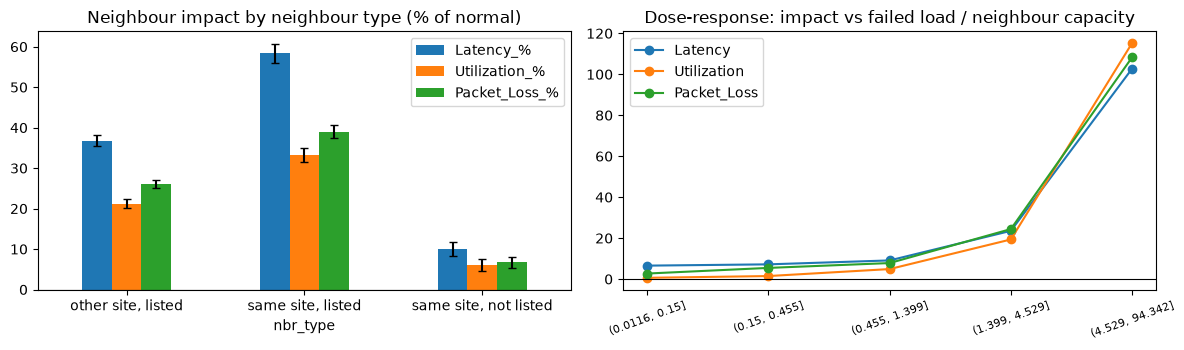

In [7]:
WEEK = 7 * 24 // GRID_STEP_H
CTRL_SHIFTS = [w * WEEK for w in CONTROL_WEEKS]
DID_VARS = ["Latency", "Utilization", "Packet_Loss", "Traffic", "Connected_Users", "Throughput", "Load"]
FAIL_VARS = ["Traffic", "Connected_Users", "Load", "Capacity", "Utilization", "Throughput"]
NORMAL_VARS = IMPACT_TARGETS + ["Traffic", "Load"]

rows, skipped = [], {"start outside grid": 0, "no absorbing neighbours": 0}
for r, se in zip(out.itertuples(), s_slot):
    c = r.ci
    if se < 3 or se >= N_T:
        skipped["start outside grid"] += 1; continue
    nbrs = A_USE.indices[A_USE.indptr[c]:A_USE.indptr[c + 1]]
    ab = nbrs[has_kpi[nbrs, se - 1] & ~down[nbrs, se - 1]]            # up and reporting just before the outage
    if len(ab) == 0:
        skipped["no absorbing neighbours"] += 1; continue
    cap_ab = G["Capacity"][ab, se - 1].astype(float); cap_sum = np.nansum(cap_ab)
    listed = set(A_NBR.indices[A_NBR.indptr[c]:A_NBR.indptr[c + 1]])
    fail = {f"fail_{v}": (float(G[v][c, se - 1]) if has_kpi[c, se - 1] else np.nan) for v in FAIL_VARS}
    sdown = site_cells_down_at(c, r.start)
    in_outage = bool(down[c, se])
    for n, capn in zip(ab, cap_ab):
        if not has_kpi[n, se] or down[n, se]:
            continue
        row = {"event_id": r.event_id, "fail_ci": c, "nbr_ci": n, "se": se, "start": r.start,
               "duration_h": r.duration_h, "in_outage": in_outage, "hour": GRID_TIMES[se].hour,
               "is_same_site": int(site_of_cell[n] == site_of_cell[c]), "is_listed": int(n in listed),
               "site_cells_down": sdown, "n_absorbing": len(ab),
               "capacity_share": capn / cap_sum if cap_sum > 0 else np.nan, **fail}
        row["expected_extra_load"] = row["fail_Load"] * row["capacity_share"]
        row["load_ratio"] = row["fail_Load"] / capn if capn > 0 else np.nan
        lw = se - WEEK
        for v in NORMAL_VARS:
            row[f"nb_{v}_last_week"] = float(G[v][n, lw]) if (lw >= 0 and has_kpi[n, lw] and not down[n, lw]) else np.nan
        ok = [sh for sh in CTRL_SHIFTS if 0 <= se - 1 + sh and se + sh < N_T
              and has_kpi[n, se - 1 + sh] and has_kpi[n, se + sh]
              and not (down[n, se - 1 + sh] or down[n, se + sh] or down[c, se - 1 + sh] or down[c, se + sh])]
        row["n_controls"] = len(ok)
        for v in DID_VARS:
            g = G[v]
            row[f"y_{v}"] = float(g[n, se]); row[f"before_{v}"] = float(g[n, se - 1])
            ev_d = row[f"y_{v}"] - row[f"before_{v}"]
            if ok:
                ct = np.mean([g[n, se + sh] - g[n, se - 1 + sh] for sh in ok])
                row[f"did_{v}"] = ev_d - ct
                row[f"normal_{v}"] = float(np.mean([g[n, se - 1 + sh] for sh in ok]))
            else:
                row[f"did_{v}"] = np.nan; row[f"normal_{v}"] = np.nan
        rows.append(row)
PAIRS = pd.DataFrame(rows)
PAIRS["Technology"] = master.Technology.to_numpy()[PAIRS.nbr_ci]
PAIRS["Region"] = master.Region.to_numpy()[PAIRS.nbr_ci]
PAIRS["nbr_type"] = np.select([(PAIRS.is_same_site == 1) & (PAIRS.is_listed == 1), PAIRS.is_same_site == 1],
                              ["same site, listed", "same site, not listed"], "other site, listed")
print(f"(outage, neighbour) pairs: {len(PAIRS):,} from {PAIRS.event_id.nunique():,} outages | skipped outages: {skipped}")
print(f"Outages whose first post-start observation falls inside the outage: "
      f"{100 * PAIRS.groupby('event_id').in_outage.first().mean():.1f}%")

def did_summary(df, by=None):
    """Event-level averages (each outage counts once), mean +/- 95% CI, as % of the normal level."""
    def one(d):
        res = {}
        ev = d.groupby("event_id")[[f"did_{v}" for v in DID_VARS] + [f"normal_{v}" for v in DID_VARS]].mean()
        for v in DID_VARS:
            x = ev[f"did_{v}"].dropna(); base = ev[f"normal_{v}"].mean()
            se_ = x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
            res[f"{v}_%"] = 100 * x.mean() / base if base else np.nan
            res[f"{v}_CI±%"] = 100 * 1.96 * se_ / base if base else np.nan
        res["outages"] = len(ev); res["pairs"] = len(d)
        return pd.Series(res)
    if by is None: return one(df).to_frame("all").T
    cols = ["event_id"] + [c for c in df.columns if c.startswith(("did_", "normal_"))]
    return df.groupby(by, observed=True)[cols].apply(one)

D_ok = PAIRS[PAIRS.in_outage & (PAIRS.n_controls > 0)]
print("\nImpact during outages (observation inside the outage), % of normal level")
display(did_summary(D_ok).round(2))
print("By neighbour type")
display(did_summary(D_ok, "nbr_type").round(2))
D_ok = D_ok.assign(load_ratio_q=pd.qcut(D_ok.load_ratio, 5, duplicates="drop"))
print("Dose-response: impact by quintile of failed load / neighbour capacity")
display(did_summary(D_ok, "load_ratio_q")[[f"{v}_%" for v in IMPACT_TARGETS] + ["pairs"]].round(2))
print("By number of neighbours sharing the load")
display(did_summary(D_ok, pd.cut(D_ok.n_absorbing, [0, 2, 4, 8, 16, 1000]))[[f"{v}_%" for v in IMPACT_TARGETS] + ["pairs"]].round(2))
print("Observation after the outage already ended (should be ~0 if the effect is caused by the outage)")
display(did_summary(PAIRS[~PAIRS.in_outage & (PAIRS.n_controls > 0)]).round(2))
het = D_ok[[f"did_{v}" for v in IMPACT_TARGETS]].describe(percentiles=[.1, .5, .9]).T
het["sd/|mean|"] = het["std"] / het["mean"].abs()
print("Heterogeneity across pairs (a large spread relative to the mean means there is variation for a model to explain)")
display(het.round(3))

dr = did_summary(D_ok, "load_ratio_q")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
m = did_summary(D_ok, "nbr_type")
m[[f"{v}_%" for v in IMPACT_TARGETS]].plot.bar(ax=axes[0], yerr=m[[f"{v}_CI±%" for v in IMPACT_TARGETS]].to_numpy().T, capsize=3)
axes[0].set_title("Neighbour impact by neighbour type (% of normal)"); axes[0].axhline(0, c="k", lw=0.8); axes[0].tick_params(axis="x", rotation=0)
for v in IMPACT_TARGETS:
    axes[1].plot(range(len(dr)), dr[f"{v}_%"], marker="o", label=v)
axes[1].set_xticks(range(len(dr))); axes[1].set_xticklabels([str(i) for i in dr.index], rotation=20, fontsize=8)
axes[1].set_title("Dose-response: impact vs failed load / neighbour capacity"); axes[1].legend(); axes[1].axhline(0, c="k", lw=0.8)
plt.tight_layout(); plt.show()
PAIRS.to_pickle(OUTPUT_DIR / "pairs.pkl")

## 8. Target definition and the modelling dataset

* **Unit:** one (outage, neighbour) pair.
* **Outages used:** those whose first observation after the start falls inside the outage, so the neighbour is measured while absorbing the displaced traffic. Shorter outages fall between two 3-hourly observations and cannot be observed.
* **Targets:** the neighbour's `Latency`, `Utilization` and `Packet_Loss` at that observation (the level).
* **The "change" view** (target − value before) is reported from the same predictions, because it isolates the outage effect.

Modelling pairs: 47,786 from 4,311 outages (69.1% of all outages)
Target summary (level during outage, and change from before)


,count,mean,std,min,25%,50%,75%,max
y_Latency,47786.0,110.027,86.347,8.500,57.635,87.073,128.612,628.674
y_Utilization,47786.0,123.143,70.566,38.282,74.144,103.994,151.795,1281.510
y_Packet_Loss,47786.0,1.295,0.751,0.025,0.700,1.151,1.795,4.322
chg_Latency,47786.0,29.413,68.333,-386.891,-0.391,8.311,25.372,470.679
chg_Utilization,47786.0,19.692,65.333,-747.054,-3.520,9.391,29.565,1234.935
chg_Packet_Loss,47786.0,0.245,0.661,-2.638,-0.041,0.113,0.468,3.069


Mean change by neighbour type


chg_Latency                chg_Utilization                chg_Packet_Loss              
                             mean     std  count            mean     std  count            mean    std  count
nbr_type                                                                                                     
other site, listed         27.464  65.261  35563          18.061  61.825  35563           0.230  0.642  35563
same site, listed          45.841  83.430   8808          32.102  80.073   8808           0.382  0.756   8808
same site, not listed       7.339  42.584   3415           4.669  52.314   3415           0.048  0.510   3415

Spearman correlation of the change with load-sharing variables


,load_ratio,expected_extra_load,capacity_share,n_absorbing,fail_Load
chg_Latency,0.431,0.092,-0.297,-0.048,0.300
chg_Utilization,0.405,0.198,-0.178,-0.059,0.349
chg_Packet_Loss,0.363,0.197,-0.151,-0.054,0.324


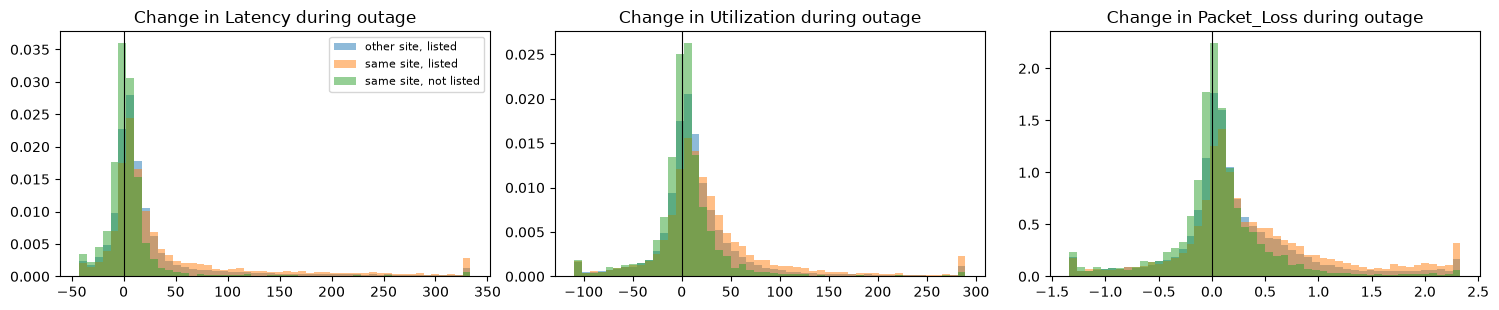

In [8]:
MD = PAIRS[PAIRS.in_outage].copy().reset_index(drop=True)
for v in IMPACT_TARGETS:
    MD[f"chg_{v}"] = MD[f"y_{v}"] - MD[f"before_{v}"]
print(f"Modelling pairs: {len(MD):,} from {MD.event_id.nunique():,} outages "
      f"({100 * MD.event_id.nunique() / len(out):.1f}% of all outages)")
print("Target summary (level during outage, and change from before)")
display(MD[[f"y_{v}" for v in IMPACT_TARGETS] + [f"chg_{v}" for v in IMPACT_TARGETS]].describe().T.round(3))
print("Mean change by neighbour type")
display(MD.groupby("nbr_type")[[f"chg_{v}" for v in IMPACT_TARGETS]].agg(["mean", "std", "count"]).round(3))
print("Spearman correlation of the change with load-sharing variables")
display(MD[[f"chg_{v}" for v in IMPACT_TARGETS] + ["load_ratio", "expected_extra_load", "capacity_share", "n_absorbing", "fail_Load"]]
        .corr("spearman").loc[[f"chg_{v}" for v in IMPACT_TARGETS], ["load_ratio", "expected_extra_load", "capacity_share", "n_absorbing", "fail_Load"]].round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, v in zip(axes, IMPACT_TARGETS):
    for t, d in MD.groupby("nbr_type"):
        ax.hist(d[f"chg_{v}"].clip(*np.nanpercentile(MD[f"chg_{v}"], [1, 99])), bins=50, alpha=0.5, label=t, density=True)
    ax.set_title(f"Change in {v} during outage"); ax.axvline(0, c="k", lw=0.8)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 9. Splits A and B

* A fixed 20% of **sites** is drawn as the unseen-site group.
* Any pair that touches an unseen site (as the failed cell or the neighbour) is **excluded from training and validation**.
* **Split A** uses pairs where both cells are on development sites, split by outage start: Jan–Apr train, May validation, June test.
* **Split B** uses pairs whose failed cell is on an unseen site. These are evaluated in June (new sites and a future period) and over all months (new sites only).

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
n_sites = len(SITES)
unseen_site = np.zeros(n_sites, bool)
unseen_site[rng.choice(n_sites, size=int(round(UNSEEN_SITE_FRACTION * n_sites)), replace=False)] = True
fu = unseen_site[site_of_cell[MD.fail_ci.to_numpy()]]
nu = unseen_site[site_of_cell[MD.nbr_ci.to_numpy()]]
dev = ~fu & ~nu
MD["split_A"] = np.select([dev & (MD.start <= TRAIN_END), dev & (MD.start > TRAIN_END) & (MD.start <= VALID_END),
                           dev & (MD.start > VALID_END)], ["train", "valid", "test"], "-")
MD["unseen_all"] = fu
MD["unseen_june"] = fu & (MD.start > VALID_END)

SETS = {"train": MD[MD.split_A == "train"], "valid": MD[MD.split_A == "valid"], "test": MD[MD.split_A == "test"],
        "unseen_june": MD[MD.unseen_june], "unseen_all": MD[MD.unseen_all]}
split_tab = pd.DataFrame({k: {"pairs": len(v), "outages": v.event_id.nunique(), "failed_cells": v.fail_ci.nunique(),
                              "same_site_%": 100 * v.is_same_site.mean(),
                              **{f"mean_chg_{t}": v[f"chg_{t}"].mean() for t in IMPACT_TARGETS}}
                          for k, v in SETS.items()}).T
print(f"Unseen sites: {unseen_site.sum():,} of {n_sites:,} | pairs excluded (development failed cell, unseen neighbour): "
      f"{int((~fu & nu).sum()):,}")
display(split_tab.round(3))
assert not set(SETS["train"].fail_ci).intersection(SETS["unseen_all"].fail_ci), "unseen cells leaked into training"

Unseen sites: 1,200 of 6,000 | pairs excluded (development failed cell, unseen neighbour): 5,712


,pairs,outages,failed_cells,same_site_%,mean_chg_Latency,mean_chg_Utilization,mean_chg_Packet_Loss
train,20884.0,2209.0,2079.0,30.052,29.030,19.136,0.238
valid,5660.0,606.0,592.0,30.477,31.215,21.852,0.266
test,5863.0,623.0,619.0,29.968,31.123,19.835,0.250
unseen_june,1812.0,162.0,159.0,25.497,34.404,26.230,0.313
unseen_all,9667.0,873.0,796.0,25.499,29.757,21.028,0.257


## 10. Feature sets

All features are known **before** the outage. The neighbour's KPI block uses the last observation before the outage (*t*), *t* − 3 h and *t* − 6 h. The nested sets are used for the ablation in section 14.

| Set | Adds |
|---|---|
| F1 | Neighbour's 9 current KPIs only |
| F2 | + the 36 lookback features (lag-1, lag-2, mean2, trend2): the 45 KPI features from the proposal |
| F3 | + failed-cell load and load sharing |
| F4 | + the neighbour's same-slot value last week |
| Full | + context (hour, same-site / listed flags, site cells already down) |

In [10]:
Xk = kpi_block(MD.nbr_ci.to_numpy(), MD.se.to_numpy() - 1, prefix="nb_")
Xk.index = MD.index
MD = pd.concat([MD.drop(columns=[c for c in Xk.columns if c in MD.columns]), Xk], axis=1)
MD["hour_sin"] = np.sin(2 * np.pi * MD.hour / 24); MD["hour_cos"] = np.cos(2 * np.pi * MD.hour / 24)
for k in SETS: SETS[k] = MD.loc[SETS[k].index]

NB_CUR = [f"nb_{v}" for v in VARS9]
NB_LOOKBACK = [f"nb_{v}_{s}" for v in VARS9 for s in ["lag1", "lag2", "mean2", "trend2"]]
FAIL = [f"fail_{v}" for v in FAIL_VARS]
SHARE = ["n_absorbing", "capacity_share", "expected_extra_load", "load_ratio"]
NORMAL = [f"nb_{v}_last_week" for v in NORMAL_VARS]
CTX = ["hour", "hour_sin", "hour_cos", "is_same_site", "is_listed", "site_cells_down"]
FEATURE_SETS = {
    "F1: neighbour current KPIs (9)": NB_CUR,
    "F2: + 6-h lookback (45)": NB_CUR + NB_LOOKBACK,
    "F3: + failed load & sharing": NB_CUR + NB_LOOKBACK + FAIL + SHARE,
    "F4: + last-week normal": NB_CUR + NB_LOOKBACK + FAIL + SHARE + NORMAL,
    "Full: + context": NB_CUR + NB_LOOKBACK + FAIL + SHARE + NORMAL + CTX,
    "Full without topology flags": NB_CUR + NB_LOOKBACK + FAIL + SHARE + NORMAL + ["hour", "hour_sin", "hour_cos", "site_cells_down"],
}
FEATURES = FEATURE_SETS["Full: + context"]
for k, v in FEATURE_SETS.items(): print(f"{k}: {len(v)} features")
miss = MD[FEATURES].isna().mean().sort_values(ascending=False)
print("Features with missing values (imputed with the training median):", miss[miss > 0].round(3).to_dict())

F1: neighbour current KPIs (9): 9 features
F2: + 6-h lookback (45): 45 features
F3: + failed load & sharing: 55 features
F4: + last-week normal: 60 features
Full: + context: 66 features
Full without topology flags: 64 features
Features with missing values (imputed with the training median): {'nb_Packet_Loss_last_week': 0.035, 'nb_Load_last_week': 0.035, 'nb_Traffic_last_week': 0.035, 'nb_Utilization_last_week': 0.035, 'nb_Latency_last_week': 0.035, 'nb_Utilization_mean2': 0.0, 'nb_Capacity_mean2': 0.0, 'nb_Connected_Users_mean2': 0.0, 'nb_Latency_mean2': 0.0, 'nb_Traffic_mean2': 0.0, 'nb_Packet_Loss_mean2': 0.0, 'nb_Alarm_Count_mean2': 0.0, 'nb_Load_mean2': 0.0, 'nb_Throughput_mean2': 0.0, 'nb_Packet_Loss_trend2': 0.0, 'nb_Packet_Loss_lag2': 0.0, 'nb_Traffic_lag2': 0.0, 'nb_Traffic_trend2': 0.0, 'nb_Throughput_lag2': 0.0, 'nb_Throughput_trend2': 0.0, 'nb_Load_lag2': 0.0, 'nb_Capacity_trend2': 0.0, 'nb_Load_trend2': 0.0, 'nb_Utilization_lag2': 0.0, 'nb_Capacity_lag2': 0.0, 'nb_Utilizati

## 11. Evaluation helpers

* **MAE / RMSE:** in the KPI's own units (ms for latency, utilization points, packet-loss points).
* **R² level:** on the KPI value during the outage.
* **R² change:** on (value − value before), using the same predictions.
* **Skill:** % reduction in MAE versus the best baseline.
* **Bootstrap:** confidence intervals resample **outages**, not rows, because neighbours of the same outage are correlated.

In [11]:
def reg_metrics(y, p, before):
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
            "R2_level": r2_score(y, p), "R2_change": r2_score(y - before, p - before)}

def boot_mae(y, preds, groups, n=N_BOOT, seed=RANDOM_STATE):
    """preds: dict name -> prediction array. Returns {name: (lo, hi)} 95% CI of MAE, resampling outages,
    and a function giving the CI of MAE(a) - MAE(b)."""
    ug, inv = np.unique(groups, return_inverse=True)
    rng = np.random.default_rng(seed)
    W = np.stack([np.bincount(rng.integers(0, len(ug), len(ug)), minlength=len(ug)) for _ in range(n)])
    cnt = np.bincount(inv, minlength=len(ug))
    sums = {k: np.bincount(inv, weights=np.abs(y - p), minlength=len(ug)) for k, p in preds.items()}
    maes = {k: (W @ s) / (W @ cnt) for k, s in sums.items()}
    ci = {k: tuple(np.percentile(v, [2.5, 97.5])) for k, v in maes.items()}
    diff = lambda a, b: tuple(np.percentile(maes[a] - maes[b], [2.5, 97.5]))
    return ci, diff

## 12. Baselines and tuned models

**Baselines** (no learning):
1. *Persistence:* the value just before the outage.
2. *Persistence + average jump:* adds the mean change seen in training.
3. *Persistence + average jump by neighbour type:* the same, with a separate jump for each neighbour type.
4. *Same slot last week:* falls back to persistence when last week is missing.

**Models:** Ridge regression, Decision Tree, Random Forest and Gradient Boosting, tuned on split A validation MAE. Every model is fitted on split A training data only, then scored once on the test set and both unseen-site sets.

In [12]:
def imp(): return ("imputer", SimpleImputer(strategy="median"))
GRID = {
    "Ridge": (lambda alpha: Pipeline([imp(), ("scaler", StandardScaler()), ("model", Ridge(alpha=alpha))]),
              [{"alpha": a} for a in ([1.0] if FAST_MODE else [0.1, 1.0, 10.0, 100.0])]),
    "Decision Tree": (lambda max_depth, min_samples_leaf: Pipeline([imp(), ("model", DecisionTreeRegressor(
                          max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=RANDOM_STATE))]),
                      [{"max_depth": d, "min_samples_leaf": l} for d in ([6] if FAST_MODE else [4, 6, 10, 14])
                                                                     for l in ([20] if FAST_MODE else [5, 20, 50])]),
    "Random Forest": (lambda max_depth, min_samples_leaf, max_features: Pipeline([imp(), ("model", RandomForestRegressor(
                          n_estimators=150 if FAST_MODE else 400, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                          max_features=max_features, n_jobs=-1, random_state=RANDOM_STATE))]),
                      [{"max_depth": d, "min_samples_leaf": l, "max_features": f}
                       for d in ([12] if FAST_MODE else [10, 20, None]) for l in ([5] if FAST_MODE else [2, 5, 15])
                       for f in ([0.5] if FAST_MODE else [0.33, 0.6])]),
}
if INCLUDE_BOOSTING:
    GRID["Gradient Boosting"] = (
        lambda learning_rate, max_leaf_nodes, min_samples_leaf: HistGradientBoostingRegressor(
            learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes, min_samples_leaf=min_samples_leaf,
            max_iter=1000, early_stopping=True, validation_fraction=0.15, random_state=RANDOM_STATE),
        [{"learning_rate": a, "max_leaf_nodes": m, "min_samples_leaf": l}
         for a in ([0.1] if FAST_MODE else [0.03, 0.1]) for m in ([15] if FAST_MODE else [15, 31])
         for l in ([20] if FAST_MODE else [10, 40])])

EVAL_SETS = ["valid", "test", "unseen_june", "unseen_all"]
X = {k: v[FEATURES].to_numpy(np.float32) for k, v in SETS.items()}
results, tuning, BEST, PRED = [], [], {}, {}
for tgt in IMPACT_TARGETS:
    y = {k: v[f"y_{tgt}"].to_numpy(float) for k, v in SETS.items()}
    b = {k: v[f"before_{tgt}"].to_numpy(float) for k, v in SETS.items()}
    tr = SETS["train"]
    jump = float((tr[f"y_{tgt}"] - tr[f"before_{tgt}"]).mean())
    jump_by_type = (tr[f"y_{tgt}"] - tr[f"before_{tgt}"]).groupby(tr.nbr_type).mean()
    def lw(k):
        x = SETS[k][f"nb_{tgt}_last_week"].to_numpy(float); return np.where(np.isnan(x), b[k], x)
    preds = {"Baseline: persistence": {k: b[k] for k in SETS},
             "Baseline: persistence + avg jump": {k: b[k] + jump for k in SETS},
             "Baseline: persistence + jump by type": {k: b[k] + SETS[k].nbr_type.map(jump_by_type).fillna(jump).to_numpy() for k in SETS},
             "Baseline: same slot last week": {k: lw(k) for k in SETS}}
    best_overall = None
    for mname, (factory, grid) in GRID.items():
        best = None
        t0 = time.time()
        for params in grid:
            m = factory(**params).fit(X["train"], y["train"])
            mae = mean_absolute_error(y["valid"], m.predict(X["valid"]))
            tuning.append({"Target": tgt, "Model": mname, "Params": json.dumps(params), "Valid_MAE": mae})
            if best is None or mae < best[0]: best = (mae, params, m)
        mae, params, m = best
        preds[mname] = {k: (m.predict(X[k]) if len(X[k]) else np.array([])) for k in SETS}
        BEST.setdefault(tgt, {})[mname] = {"model": m, "params": params, "valid_MAE": mae}
        if best_overall is None or mae < best_overall[0]: best_overall = (mae, mname)
        print(f"{tgt:12s} {mname:18s} best {params} | valid MAE {mae:.4f} | {time.time() - t0:.0f}s")
    BEST[tgt]["_best"] = best_overall[1]
    PRED[tgt] = preds
    base_names = [n for n in preds if n.startswith("Baseline")]
    best_base = min(base_names, key=lambda n: mean_absolute_error(y["valid"], preds[n]["valid"]))
    BEST[tgt]["_best_baseline"] = best_base
    for name, pr in preds.items():
        for k in EVAL_SETS:
            if len(y[k]) == 0: continue
            results.append({"Target": tgt, "Model": name, "Set": k, "Pairs": len(y[k]), **reg_metrics(y[k], pr[k], b[k])})
    print(f"  -> selected by validation: {best_overall[1]} | strongest baseline on validation: {best_base}")
RES = pd.DataFrame(results)
RES.to_csv(OUTPUT_DIR / "results_all_models.csv", index=False)
pd.DataFrame(tuning).to_csv(OUTPUT_DIR / "tuning.csv", index=False)

Latency      Ridge              best {'alpha': 100.0} | valid MAE 27.2776 | 1s
Latency      Decision Tree      best {'max_depth': 14, 'min_samples_leaf': 50} | valid MAE 22.2921 | 17s
Latency      Random Forest      best {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.6} | valid MAE 20.1214 | 313s
Latency      Gradient Boosting  best {'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 10} | valid MAE 19.8428 | 9s
  -> selected by validation: Gradient Boosting | strongest baseline on validation: Baseline: same slot last week
Utilization  Ridge              best {'alpha': 100.0} | valid MAE 21.6620 | 1s
Utilization  Decision Tree      best {'max_depth': 14, 'min_samples_leaf': 50} | valid MAE 21.2813 | 14s
Utilization  Random Forest      best {'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.6} | valid MAE 18.6609 | 298s
Utilization  Gradient Boosting  best {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 40} | valid MAE 18.7977 | 8s
 

## 13. Results with confidence intervals

The tables show every model and baseline on split A test and on split B. The bootstrap table compares the validation-selected model with the strongest baseline on each test set.


=== Split A: June test (development sites) ===


,Target,Model,Pairs,MAE,RMSE,R2_level,R2_change,MAE_skill_vs_best_baseline_%
0,Latency,Baseline: persistence,5863,38.2760,77.9624,0.2364,-0.1896,-6.3649
1,Latency,Baseline: persistence + avg jump,5863,42.9317,71.5113,0.3575,-0.0009,-19.3026
2,Latency,Baseline: persistence + jump by type,5863,42.1569,70.7491,0.3712,0.0204,-17.1497
3,Latency,Baseline: same slot last week,5863,35.9855,77.0599,0.2540,-0.1622,0.0000
4,Latency,Ridge,5863,26.6501,45.5145,0.7397,0.5946,25.9421
5,Latency,Decision Tree,5863,22.4634,42.0519,0.7778,0.6539,37.5765
6,Latency,Random Forest,5863,20.1397,38.5108,0.8137,0.7097,44.0338
7,Latency,Gradient Boosting,5863,19.6890,38.4479,0.8143,0.7107,45.2863
8,Utilization,Baseline: persistence,5863,36.9566,70.4255,0.0946,-0.0862,-22.3129
9,Utilization,Baseline: persistence + avg jump,5863,36.6447,67.5783,0.1664,-0.0001,-21.2806



=== Split B: unseen sites, June ===


,Target,Model,Pairs,MAE,RMSE,R2_level,R2_change,MAE_skill_vs_best_baseline_%
0,Latency,Baseline: persistence,1812,39.2455,78.6228,0.2156,-0.2368,-4.3261
1,Latency,Baseline: persistence + avg jump,1812,42.0030,70.9000,0.3621,-0.0058,-11.6563
2,Latency,Baseline: persistence + jump by type,1812,41.0711,70.1565,0.3754,0.0152,-9.1789
3,Latency,Baseline: same slot last week,1812,37.6181,77.8354,0.2312,-0.2122,0.0000
4,Latency,Ridge,1812,25.7462,43.5693,0.7591,0.6202,31.5591
5,Latency,Decision Tree,1812,22.8495,43.3544,0.7615,0.6239,39.2595
6,Latency,Random Forest,1812,20.4302,39.4319,0.8027,0.6889,45.6905
7,Latency,Gradient Boosting,1812,20.6531,40.3662,0.7932,0.6740,45.0979
8,Utilization,Baseline: persistence,1812,38.2026,76.1640,0.0662,-0.1346,-17.0881
9,Utilization,Baseline: persistence + avg jump,1812,36.3558,71.8557,0.1689,-0.0098,-11.4281



=== Split B: unseen sites, all months ===


,Target,Model,Pairs,MAE,RMSE,R2_level,R2_change,MAE_skill_vs_best_baseline_%
0,Latency,Baseline: persistence,9667,35.4185,73.1960,0.2603,-0.1980,-5.7561
1,Latency,Baseline: persistence + avg jump,9667,39.9440,66.8785,0.3825,-0.0001,-19.2687
2,Latency,Baseline: persistence + jump by type,9667,39.1430,66.2212,0.3946,0.0194,-16.8772
3,Latency,Baseline: same slot last week,9667,33.4908,72.4188,0.2760,-0.1727,0.0000
4,Latency,Ridge,9667,25.9876,44.9009,0.7217,0.5492,22.4037
5,Latency,Decision Tree,9667,22.2961,43.2905,0.7413,0.5810,33.4260
6,Latency,Random Forest,9667,19.7696,39.2290,0.7875,0.6559,40.9700
7,Latency,Gradient Boosting,9667,19.5325,39.1342,0.7886,0.6576,41.6780
8,Utilization,Baseline: persistence,9667,34.6572,68.7147,0.0810,-0.1033,-20.3881
9,Utilization,Baseline: persistence + avg jump,9667,34.0648,65.4454,0.1664,-0.0008,-18.3304


,Target,Set,Model,MAE,MAE_CI,Best baseline,Baseline_MAE,MAE_reduction_%,Diff_CI,Significant
0,Latency,test,Gradient Boosting,19.6890,18.429-21.070,Baseline: same slot last week,35.9855,45.2863,-18.328 to -14.529,True
1,Latency,unseen_june,Gradient Boosting,20.6531,18.013-23.484,Baseline: same slot last week,37.6181,45.0979,-20.426 to -13.831,True
2,Latency,unseen_all,Gradient Boosting,19.5325,18.461-20.610,Baseline: same slot last week,33.4908,41.6780,-15.608 to -12.588,True
3,Utilization,test,Random Forest,18.1266,16.790-19.709,Baseline: same slot last week,30.2148,40.0078,-13.873 to -10.650,True
4,Utilization,unseen_june,Random Forest,19.4976,16.580-22.861,Baseline: same slot last week,32.6272,40.2412,-15.814 to -10.691,True
5,Utilization,unseen_all,Random Forest,17.8246,16.576-19.061,Baseline: same slot last week,28.7879,38.0830,-12.281 to -9.959,True
6,Packet_Loss,test,Gradient Boosting,0.2493,0.238-0.262,Baseline: same slot last week,0.4038,38.2618,-0.174 to -0.139,True
7,Packet_Loss,unseen_june,Gradient Boosting,0.2550,0.232-0.279,Baseline: same slot last week,0.4261,40.1664,-0.204 to -0.140,True
8,Packet_Loss,unseen_all,Gradient Boosting,0.2428,0.233-0.253,Baseline: same slot last week,0.3796,36.0301,-0.151 to -0.125,True


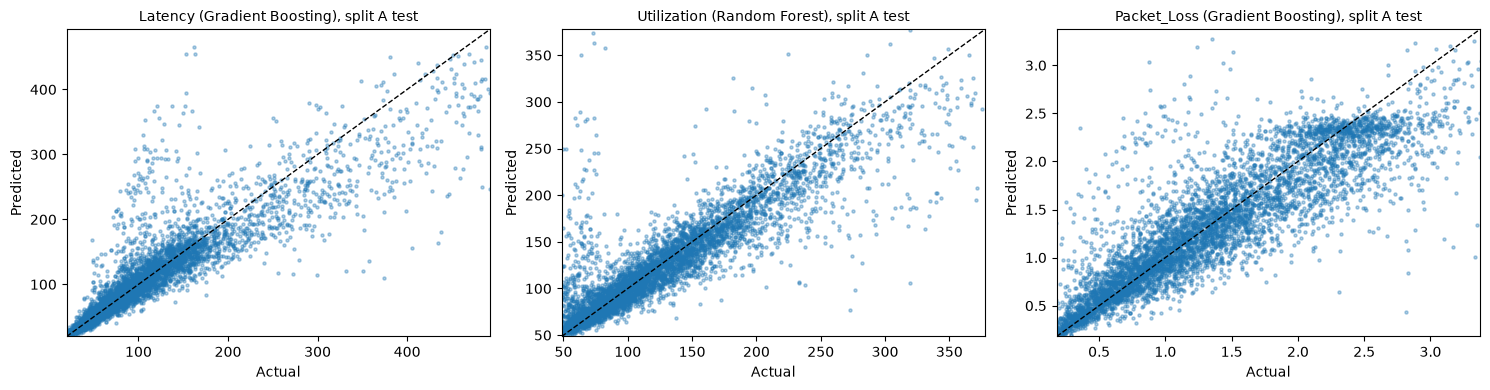

In [13]:
for k, title in [("test", "Split A: June test (development sites)"), ("unseen_june", "Split B: unseen sites, June"),
                 ("unseen_all", "Split B: unseen sites, all months")]:
    print(f"\n=== {title} ===")
    t = RES[RES.Set == k].drop(columns="Set").copy()
    for tgt in IMPACT_TARGETS:
        base = t[(t.Target == tgt) & (t.Model == BEST[tgt]["_best_baseline"])].MAE.iloc[0]
        t.loc[t.Target == tgt, "MAE_skill_vs_best_baseline_%"] = 100 * (1 - t.loc[t.Target == tgt, "MAE"] / base)
    display(t.round(4).reset_index(drop=True))

ci_rows = []
for tgt in IMPACT_TARGETS:
    sel, base = BEST[tgt]["_best"], BEST[tgt]["_best_baseline"]
    for k in ["test", "unseen_june", "unseen_all"]:
        if len(SETS[k]) == 0: continue
        y = SETS[k][f"y_{tgt}"].to_numpy(float)
        ci, diff = boot_mae(y, {sel: PRED[tgt][sel][k], base: PRED[tgt][base][k]}, SETS[k].event_id.to_numpy())
        m_sel, m_base = mean_absolute_error(y, PRED[tgt][sel][k]), mean_absolute_error(y, PRED[tgt][base][k])
        d_lo, d_hi = diff(sel, base)
        ci_rows.append({"Target": tgt, "Set": k, "Model": sel, "MAE": m_sel, "MAE_CI": f"{ci[sel][0]:.3f}-{ci[sel][1]:.3f}",
                        "Best baseline": base, "Baseline_MAE": m_base, "MAE_reduction_%": 100 * (1 - m_sel / m_base),
                        "Diff_CI": f"{d_lo:.3f} to {d_hi:.3f}", "Significant": d_hi < 0})
CI = pd.DataFrame(ci_rows); display(CI.round(4)); CI.to_csv(OUTPUT_DIR / "results_with_ci.csv", index=False)

fig, axes = plt.subplots(1, len(IMPACT_TARGETS), figsize=(5 * len(IMPACT_TARGETS), 4))
for ax, tgt in zip(np.atleast_1d(axes), IMPACT_TARGETS):
    y = SETS["test"][f"y_{tgt}"].to_numpy(float); p = PRED[tgt][BEST[tgt]["_best"]]["test"]
    ax.scatter(y, p, s=5, alpha=0.35)
    lo, hi = np.nanpercentile(np.r_[y, p], [0.5, 99.5]); ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_xlabel("Actual"); ax.set_ylabel("Predicted")
    ax.set_title(f"{tgt} ({BEST[tgt]['_best']}), split A test", fontsize=10)
plt.tight_layout(); plt.show()

## 14. Feature ablation

Each feature set from section 10 is refitted with the **same** model type and hyperparameters (the validation-selected model for each target). Only the inputs change, so any difference in test MAE comes from the features. The bootstrap CI is for the difference against the full set; a negative difference means the smaller set is better.

In [14]:
abl_rows = []
for tgt in IMPACT_TARGETS:
    sel = BEST[tgt]["_best"]; factory, _ = GRID[sel]; params = BEST[tgt][sel]["params"]
    y_tr = SETS["train"][f"y_{tgt}"].to_numpy(float)
    preds = {}
    for fs, cols in FEATURE_SETS.items():
        m = factory(**params).fit(SETS["train"][cols].to_numpy(np.float32), y_tr)
        preds[fs] = {k: m.predict(SETS[k][cols].to_numpy(np.float32)) for k in ["test", "unseen_june"] if len(SETS[k])}
    for k in ["test", "unseen_june"]:
        if len(SETS[k]) == 0: continue
        y = SETS[k][f"y_{tgt}"].to_numpy(float); bfr = SETS[k][f"before_{tgt}"].to_numpy(float)
        ci, diff = boot_mae(y, {fs: preds[fs][k] for fs in FEATURE_SETS}, SETS[k].event_id.to_numpy())
        for fs in FEATURE_SETS:
            lo, hi = diff(fs, "Full: + context") if fs != "Full: + context" else (0.0, 0.0)
            abl_rows.append({"Target": tgt, "Set": k, "Feature set": fs, "n_features": len(FEATURE_SETS[fs]),
                             **reg_metrics(y, preds[fs][k], bfr), "MAE_diff_vs_full_CI": f"{lo:.3f} to {hi:.3f}",
                             "Worse_than_full": lo > 0})
ABL = pd.DataFrame(abl_rows); ABL.to_csv(OUTPUT_DIR / "feature_ablation.csv", index=False)
for k in ["test", "unseen_june"]:
    print(f"\n=== Ablation on {k} ===")
    display(ABL[ABL.Set == k].pivot_table(index="Feature set", columns="Target", values="MAE", sort=False).round(4))
display(ABL[ABL.Set == "test"].drop(columns="Set").round(4))


=== Ablation on test ===


Target,Latency,Utilization,Packet_Loss
Feature set,,,
F1: neighbour current KPIs (9),38.0024,37.7692,0.4609
F2: + 6-h lookback (45),37.5926,35.9945,0.4431
F3: + failed load & sharing,25.6018,26.4693,0.3435
F4: + last-week normal,22.7012,19.7606,0.2807
Full: + context,19.6890,18.1266,0.2493
Full without topology flags,22.1063,19.0962,0.2719



=== Ablation on unseen_june ===


Target,Latency,Utilization,Packet_Loss
Feature set,,,
F1: neighbour current KPIs (9),38.2548,38.4634,0.4703
F2: + 6-h lookback (45),37.9535,36.9968,0.4508
F3: + failed load & sharing,25.2587,26.9865,0.3426
F4: + last-week normal,22.5420,20.9785,0.2820
Full: + context,20.6531,19.4976,0.2550
Full without topology flags,22.2021,20.3322,0.2746


,Target,Feature set,n_features,MAE,RMSE,R2_level,R2_change,MAE_diff_vs_full_CI,Worse_than_full
0,Latency,F1: neighbour current KPIs (9),9,38.0024,63.4218,0.4947,0.2128,17.017 to 19.638,True
1,Latency,F2: + 6-h lookback (45),45,37.5926,62.7341,0.5056,0.2298,16.634 to 19.130,True
2,Latency,F3: + failed load & sharing,55,25.6018,44.8607,0.7472,0.6061,5.262 to 6.510,True
3,Latency,F4: + last-week normal,60,22.7012,43.2168,0.7654,0.6345,2.480 to 3.559,True
4,Latency,Full: + context,66,19.6890,38.4479,0.8143,0.7107,0.000 to 0.000,False
5,Latency,Full without topology flags,64,22.1063,42.9456,0.7683,0.6390,1.970 to 2.892,True
12,Utilization,F1: neighbour current KPIs (9),9,37.7692,62.4841,0.2873,0.1450,18.417 to 20.846,True
13,Utilization,F2: + 6-h lookback (45),45,35.9945,61.3204,0.3136,0.1765,16.680 to 19.060,True
14,Utilization,F3: + failed load & sharing,55,26.4693,46.6530,0.6027,0.5234,7.574 to 9.078,True
15,Utilization,F4: + last-week normal,60,19.7606,40.0916,0.7066,0.6480,1.312 to 2.004,True


## 15. Sanity checks

1. **Shuffled target.** Train on randomly permuted targets. Test R² should be about 0 or below. Anything clearly above 0 would point to leakage in the pipeline.
2. **Overfitting.** Compare MAE on training, validation and test.
3. **Learning curve.** Refit on 25–100% of the training outages. A curve that is still falling means more data would help.
4. **Stability over time.** Error by month on the unseen sites, which cover every month.

In [15]:
san = []
for tgt in IMPACT_TARGETS:
    sel = BEST[tgt]["_best"]; factory, _ = GRID[sel]; params = BEST[tgt][sel]["params"]
    y_tr = SETS["train"][f"y_{tgt}"].to_numpy(float); y_te = SETS["test"][f"y_{tgt}"].to_numpy(float)
    yp = np.random.default_rng(RANDOM_STATE).permutation(y_tr)
    r2_shuf = r2_score(y_te, factory(**params).fit(X["train"], yp).predict(X["test"]))
    m = BEST[tgt][sel]["model"]
    row = {"Target": tgt, "Model": sel, "R2_test_shuffled_target": r2_shuf}
    for k in ["train", "valid", "test"]:
        row[f"MAE_{k}"] = mean_absolute_error(SETS[k][f"y_{tgt}"], m.predict(X[k]))
    san.append(row)
print("Shuffled-target check and train/valid/test MAE (overfitting)")
display(pd.DataFrame(san).round(4))

ev_tr = SETS["train"].event_id.unique(); rng = np.random.default_rng(RANDOM_STATE); rng.shuffle(ev_tr)
lc = []
for frac in [0.25, 0.5, 0.75, 1.0]:
    keep = SETS["train"].event_id.isin(ev_tr[: max(1, int(frac * len(ev_tr)))]).to_numpy()
    for tgt in IMPACT_TARGETS:
        sel = BEST[tgt]["_best"]; factory, _ = GRID[sel]
        m = factory(**BEST[tgt][sel]["params"]).fit(X["train"][keep], SETS["train"][f"y_{tgt}"].to_numpy(float)[keep])
        lc.append({"train_fraction": frac, "train_pairs": int(keep.sum()), "Target": tgt,
                   "test_MAE": mean_absolute_error(SETS["test"][f"y_{tgt}"], m.predict(X["test"]))})
LC = pd.DataFrame(lc)
display(LC.pivot_table(index=["train_fraction", "train_pairs"], columns="Target", values="test_MAE").round(4))

if len(SETS["unseen_all"]):
    u = SETS["unseen_all"].assign(month=SETS["unseen_all"].start.dt.month)
    mon = []
    for tgt in IMPACT_TARGETS:
        sel, base = BEST[tgt]["_best"], BEST[tgt]["_best_baseline"]
        p, pb = PRED[tgt][sel]["unseen_all"], PRED[tgt][base]["unseen_all"]
        for mth, idx in u.groupby("month").indices.items():
            yy = u[f"y_{tgt}"].to_numpy(float)[idx]
            mon.append({"Target": tgt, "month": mth, "pairs": len(idx), "MAE_model": mean_absolute_error(yy, p[idx]),
                        "MAE_best_baseline": mean_absolute_error(yy, pb[idx])})
    MON = pd.DataFrame(mon); MON["skill_%"] = 100 * (1 - MON.MAE_model / MON.MAE_best_baseline)
    print("Unseen sites by month (months 1-4 overlap the training period; 5-6 are later)")
    display(MON.pivot_table(index="month", columns="Target", values=["MAE_model", "skill_%"]).round(3))

Shuffled-target check and train/valid/test MAE (overfitting)


,Target,Model,R2_test_shuffled_target,MAE_train,MAE_valid,MAE_test
0,Latency,Gradient Boosting,-0.0016,14.8854,19.8428,19.6890
1,Utilization,Random Forest,0.0034,7.4891,18.6609,18.1266
2,Packet_Loss,Gradient Boosting,-0.0084,0.2030,0.2507,0.2493


,Target,Latency,Packet_Loss,Utilization
train_fraction,train_pairs,,,
0.25,5228,21.4103,0.2577,19.1380
0.50,10453,20.1347,0.2543,18.5637
0.75,15655,19.9038,0.2522,18.2114
1.00,20884,19.6890,0.2493,18.1266


Unseen sites by month (months 1-4 overlap the training period; 5-6 are later)


MAE_model                         skill_%                        
Target   Latency Packet_Loss Utilization Latency Packet_Loss Utilization
month                                                                   
1         20.594       0.261      20.010  41.342      37.089      38.890
2         20.598       0.251      17.822  39.365      34.331      38.317
3         17.265       0.224      16.009  37.571      31.025      33.057
4         18.448       0.233      16.910  42.573      35.234      37.230
5         19.413       0.232      16.490  42.192      36.082      38.914
6         20.653       0.255      19.498  45.098      40.166      40.241

## 15b. Rolling time-series cross-validation

The main evaluation uses one fixed chronological split (Jan–Apr train, May validation, June test). Rolling cross-validation checks that the selected Gradient Boosting settings work just as well on other time windows. The training window grows month by month, and the model is tested on the following month.

* **Development sites only:** both the failed cell and the neighbour are on development sites, the same rule as the main split.
* **Each outage's neighbours stay together:** folds are split by month, so all rows of one outage fall in the same fold.
* **The May fold is optimistic:** May is the month the settings were tuned on, so the March, April and June folds are the independent checks.
* **Comparison:** each fold also reports the strongest baseline rule (same slot last week), so the error reduction can be compared across folds.

Rolling time-series CV, Gradient Boosting, development sites only


MAE                         Reduction_%                         R2_change                        
Target                                                          Latency Utilization Packet_Loss     Latency Utilization Packet_Loss   Latency Utilization Packet_Loss
Fold           Test_rows Test_outages Note                                                                                                                           
Jan-Feb -> Mar 5320      565                                     19.740      18.639       0.245      42.991      38.103      36.647     0.684       0.682       0.679
Jan-Mar -> Apr 4742      503                                     20.162      18.089       0.244      41.686      36.344      35.781     0.679       0.673       0.723
Jan-Apr -> May 5660      606          tuning month (optimistic)  19.843      18.798       0.251      43.504      37.925      37.029     0.691       0.674       0.699
Jan-May -> Jun 5863      623                                     19.677      18.910       0.251      45.320      37.415      37.910     0.716       0.675       0.698

Independent folds (excluding the tuning month): MAE range Latency 19.7-20.2, Utilization 18.1-18.9, Packet_Loss 0.244-0.251


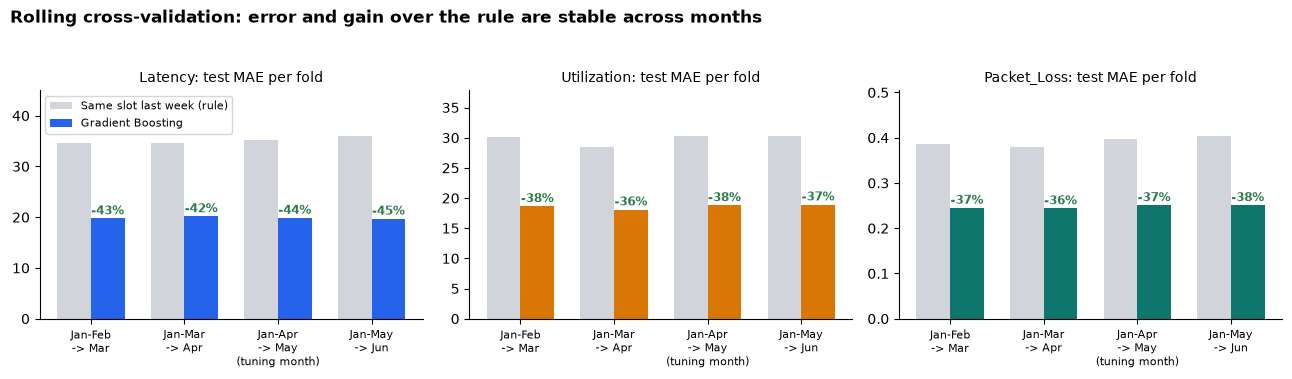

In [16]:
KPI_COLOR = {"Latency": "#2563EB", "Utilization": "#D97706", "Packet_Loss": "#0F766E"}
FIG_DIR = OUTPUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

dev_rows = MD[~fu & ~nu].copy()                      # same development-site rule as split A
dev_rows["month"] = dev_rows.start.dt.month
months = sorted(dev_rows.month.unique())
cv_folds = [{"train_months": months[:i], "test_month": months[i]} for i in range(2, len(months))]
gb_factory = GRID["Gradient Boosting"][0]
month_name = lambda m: pd.Timestamp(2025, m, 1).strftime("%b")

cv_rows = []
for fold in cv_folds:
    tr = dev_rows[dev_rows.month.isin(fold["train_months"])]
    te = dev_rows[dev_rows.month == fold["test_month"]]
    label = f"{month_name(fold['train_months'][0])}-{month_name(fold['train_months'][-1])} -> {month_name(fold['test_month'])}"
    X_tr, X_te = tr[FEATURES].to_numpy(np.float32), te[FEATURES].to_numpy(np.float32)
    for tgt in IMPACT_TARGETS:
        m = gb_factory(**BEST[tgt]["Gradient Boosting"]["params"]).fit(X_tr, tr[f"y_{tgt}"].to_numpy(float))
        y, b, p = te[f"y_{tgt}"].to_numpy(float), te[f"before_{tgt}"].to_numpy(float), m.predict(X_te)
        lw = te[f"nb_{tgt}_last_week"].to_numpy(float); lw = np.where(np.isnan(lw), b, lw)
        cv_rows.append({"Fold": label, "Test_month": fold["test_month"], "Train_rows": len(tr), "Test_rows": len(te),
                        "Test_outages": te.event_id.nunique(), "Target": tgt,
                        "MAE": mean_absolute_error(y, p), "Rule_MAE": mean_absolute_error(y, lw),
                        "Reduction_%": 100 * (1 - mean_absolute_error(y, p) / mean_absolute_error(y, lw)),
                        "R2_level": r2_score(y, p), "R2_change": r2_score(y - b, p - b),
                        "Note": "tuning month (optimistic)" if pd.Timestamp(2025, fold["test_month"], 1) <= VALID_END
                                and pd.Timestamp(2025, fold["test_month"], 1) > TRAIN_END else ""})
CV_DF = pd.DataFrame(cv_rows)
CV_DF.to_csv(OUTPUT_DIR / "rolling_cv.csv", index=False)
print("Rolling time-series CV, Gradient Boosting, development sites only")
display(CV_DF.pivot_table(index=["Fold", "Test_rows", "Test_outages", "Note"], columns="Target",
                          values=["MAE", "Reduction_%", "R2_change"], sort=False).round(3))
indep = CV_DF[CV_DF.Note == ""]
print("Independent folds (excluding the tuning month): MAE range "
      + ", ".join(f"{t} {indep[indep.Target == t].MAE.min():.3g}-{indep[indep.Target == t].MAE.max():.3g}" for t in IMPACT_TARGETS))

fig, axes = plt.subplots(1, len(IMPACT_TARGETS), figsize=(13, 3.6))
for ax, tgt in zip(np.atleast_1d(axes), IMPACT_TARGETS):
    d = CV_DF[CV_DF.Target == tgt]
    x = np.arange(len(d))
    ax.bar(x - 0.18, d.Rule_MAE, 0.36, color="#D1D5DB", label="Same slot last week (rule)")
    bars = ax.bar(x + 0.18, d.MAE, 0.36, color=KPI_COLOR[tgt], label="Gradient Boosting")
    for xi, (m_, r_, note) in enumerate(zip(d.MAE, d["Reduction_%"], d.Note)):
        ax.annotate(f"-{r_:.0f}%", (xi + 0.18, m_), xytext=(0, 3), textcoords="offset points", ha="center",
                    fontsize=8.5, color="#2F7D4F", fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels([f.replace(" -> ", "\n-> ") + ("\n(tuning month)" if n else "")
                                          for f, n in zip(d.Fold, d.Note)], fontsize=8)
    ax.set_title(f"{tgt}: test MAE per fold", fontsize=10); ax.set_ylim(0, d.Rule_MAE.max() * 1.25)
    ax.spines[["top", "right"]].set_visible(False)
np.atleast_1d(axes)[0].legend(fontsize=8, loc="upper left")
plt.suptitle("Rolling cross-validation: error and gain over the rule are stable across months", x=0.01, ha="left",
             fontweight="bold", y=1.04)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig18_rolling_cv.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

## 16. Error analysis

Errors of the validation-selected model on split A test, compared with the persistence baseline within each group. Technology, region and outage duration are used **only** to slice the errors; duration is not known when the outage starts.

In [17]:
T = SETS["test"].copy()
T["nbr_tech"] = T["Technology"]; T["fail_tech"] = master.Technology.to_numpy()[T.fail_ci]
T["load_ratio_q"] = pd.qcut(T.load_ratio, 5, duplicates="drop")
T["n_absorbing_bin"] = pd.cut(T.n_absorbing, [0, 2, 4, 8, 16, 1000])
T["duration_bin"] = pd.cut(T.duration_h, [0, 1, 2, 3, 24])
T["hour_bin"] = T.hour
for tgt in IMPACT_TARGETS:
    T[f"AE_{tgt}"] = np.abs(T[f"y_{tgt}"] - PRED[tgt][BEST[tgt]["_best"]]["test"])
    T[f"AEb_{tgt}"] = np.abs(T[f"y_{tgt}"] - T[f"before_{tgt}"])
def by(col):
    g = T.groupby(col, observed=True)
    res = pd.DataFrame({"pairs": g.size()})
    for tgt in IMPACT_TARGETS:
        res[f"MAE_{tgt}"] = g[f"AE_{tgt}"].mean()
        res[f"skill_vs_persistence_{tgt}_%"] = 100 * (1 - g[f"AE_{tgt}"].mean() / g[f"AEb_{tgt}"].mean())
    return res.round(3)
for col, title in [("nbr_type", "neighbour type"), ("nbr_tech", "neighbour technology"), ("fail_tech", "failed-cell technology"),
                   ("Region", "region"), ("load_ratio_q", "failed load / neighbour capacity quintile"),
                   ("n_absorbing_bin", "number of neighbours sharing the load"), ("duration_bin", "outage duration (h)"),
                   ("hour_bin", "hour of day")]:
    print(f"By {title}"); display(by(col))
tgt0 = IMPACT_TARGETS[0]
print(f"Ten largest {tgt0} errors (context)")
display(T.sort_values(f"AE_{tgt0}", ascending=False).head(10)[
    ["event_id", "nbr_type", "nbr_tech", "hour", "n_absorbing", "load_ratio", f"before_{tgt0}", f"y_{tgt0}", f"AE_{tgt0}", "duration_h"]].round(2))

By neighbour type


,pairs,MAE_Latency,skill_vs_persistence_Latency_%,MAE_Utilization,skill_vs_persistence_Utilization_%,MAE_Packet_Loss,skill_vs_persistence_Packet_Loss_%
nbr_type,,,,,,,
"other site, listed",4106,19.647,44.240,17.194,49.870,0.251,43.902
"same site, listed",1278,19.390,64.361,19.407,60.825,0.248,58.543
"same site, not listed",479,20.845,2.132,22.699,13.231,0.241,23.536


By neighbour technology


,pairs,MAE_Latency,skill_vs_persistence_Latency_%,MAE_Utilization,skill_vs_persistence_Utilization_%,MAE_Packet_Loss,skill_vs_persistence_Packet_Loss_%
nbr_tech,,,,,,,
2G,1503,43.394,50.356,31.534,47.327,0.337,45.984
3G,1579,18.835,44.767,13.890,48.004,0.215,43.876
4G,1477,9.383,49.591,11.279,55.295,0.222,49.328
5G,1304,5.074,43.429,15.559,57.060,0.220,48.683


By failed-cell technology


,pairs,MAE_Latency,skill_vs_persistence_Latency_%,MAE_Utilization,skill_vs_persistence_Utilization_%,MAE_Packet_Loss,skill_vs_persistence_Packet_Loss_%
fail_tech,,,,,,,
2G,1645,7.879,41.551,8.743,56.683,0.154,45.701
3G,1380,10.157,37.690,9.807,50.264,0.161,41.876
4G,1807,25.418,45.902,18.429,50.456,0.290,43.375
5G,1031,41.250,55.157,43.704,49.400,0.447,52.675


... (8 outputs left out)

By hour of day


,pairs,MAE_Latency,skill_vs_persistence_Latency_%,MAE_Utilization,skill_vs_persistence_Utilization_%,MAE_Packet_Loss,skill_vs_persistence_Packet_Loss_%
hour_bin,,,,,,,
0,992,16.066,53.033,12.851,74.459,0.203,66.434
3,508,15.987,44.934,12.917,43.064,0.205,34.766
6,370,21.688,49.500,18.620,55.685,0.256,53.319
9,670,18.558,48.405,17.595,45.640,0.247,43.041
12,763,22.944,48.255,21.596,41.945,0.282,39.725
15,930,17.992,46.862,16.948,40.134,0.243,39.083
18,713,21.937,52.937,24.368,46.609,0.273,47.398
21,917,22.945,43.421,20.364,39.276,0.284,34.859


Ten largest Latency errors (context)


,event_id,nbr_type,nbr_tech,hour,n_absorbing,load_ratio,before_Latency,y_Latency,AE_Latency,duration_h
34432,4510,"other site, listed",2G,12,10,17.80,189.17,161.53,304.25,1.13
33483,4377,"other site, listed",2G,12,10,20.14,154.75,152.75,302.44,2.42
18003,2339,"other site, listed",2G,18,9,36.75,155.45,163.03,291.22,2.85
38916,5090,"same site, not listed",2G,21,12,18.04,131.75,434.59,270.37,2.78
22069,2863,"other site, listed",2G,15,11,18.58,177.22,589.04,264.19,2.25
39550,5165,"same site, not listed",2G,3,13,22.42,89.32,373.90,263.38,3.10
33597,4394,"same site, not listed",2G,0,8,30.18,158.50,437.96,257.50,3.03
29320,3832,"other site, listed",2G,18,13,33.26,124.18,120.89,253.68,2.57
29891,3905,"same site, not listed",2G,18,6,46.36,115.84,405.64,249.29,2.90
30847,4026,"same site, listed",2G,0,7,52.20,112.28,117.51,249.15,3.77


### 16b. Relative error by technology

Raw MAE cannot be compared across technologies, because their KPI levels differ (2G latency averages about 120 ms, 5G about 48 ms). This table shows error as a percentage of the actual value, and the improvement over persistence, for the validation-selected model on the split A test set. The same numbers appear in Figure 4.1 of the report.

In [18]:
rows = []
for tgt in IMPACT_TARGETS:
    y = T[f"y_{tgt}"].to_numpy(float); p = PRED[tgt][BEST[tgt]["_best"]]["test"]; b = T[f"before_{tgt}"].to_numpy(float)
    for tech, idx in T.groupby("nbr_tech", observed=True).indices.items():
        mae = np.mean(np.abs(y[idx] - p[idx]))
        rows.append({"Target": tgt, "Technology": tech, "Pairs": len(idx), "Mean_actual": y[idx].mean(), "MAE": mae,
                     "Error_%_of_actual": 100 * mae / y[idx].mean(),
                     "Improvement_vs_persistence_%": 100 * (1 - mae / np.mean(np.abs(y[idx] - b[idx])))})
TECH_REL = pd.DataFrame(rows)
TECH_REL.to_csv(OUTPUT_DIR / "error_by_technology_relative.csv", index=False)
display(TECH_REL.pivot_table(index="Technology", columns="Target",
                             values=["Error_%_of_actual", "Improvement_vs_persistence_%"]).round(1))

Error_%_of_actual                         Improvement_vs_persistence_%                        
Target               Latency Packet_Loss Utilization                      Latency Packet_Loss Utilization
Technology                                                                                               
2G                      21.2        23.4        26.7                         50.4        46.0        47.3
3G                      17.2        22.4        14.9                         44.8        43.9        48.0
4G                      11.7        16.9         8.8                         49.6        49.3        55.3
5G                       9.5        12.4         8.5                         43.4        48.7        57.1

## 17. Interpretation (descriptive, not causal)

* **Permutation importance:** the increase in test MAE when one feature is shuffled.
* **Partial dependence:** how the prediction changes with the two most important load-sharing features.

Top 12 features per target (by increase in test MAE when shuffled)


,Latency,Utilization,Packet_Loss
0,load_ratio,nb_Utilization_last_week,nb_Packet_Loss_last_week
1,nb_Latency_last_week,load_ratio,load_ratio
2,nb_Latency,nb_Utilization,hour
3,is_listed,hour,nb_Packet_Loss
4,nb_Latency_mean2,fail_Load,is_listed
5,hour,is_listed,nb_Packet_Loss_mean2
6,nb_Latency_lag2,nb_Packet_Loss_last_week,nb_Utilization_last_week
7,fail_Capacity,nb_Traffic_last_week,fail_Capacity
8,nb_Latency_lag1,hour_cos,nb_Packet_Loss_lag2
9,n_absorbing,fail_Capacity,expected_extra_load


Importance summed by feature group


,Latency,Utilization,Packet_Loss
context,5.037,4.536,0.070
failed cell,1.051,2.494,0.012
last-week normal,12.950,15.880,0.194
load sharing,19.491,9.642,0.154
neighbour current,5.453,3.941,0.039
neighbour lookback,6.005,1.333,0.032


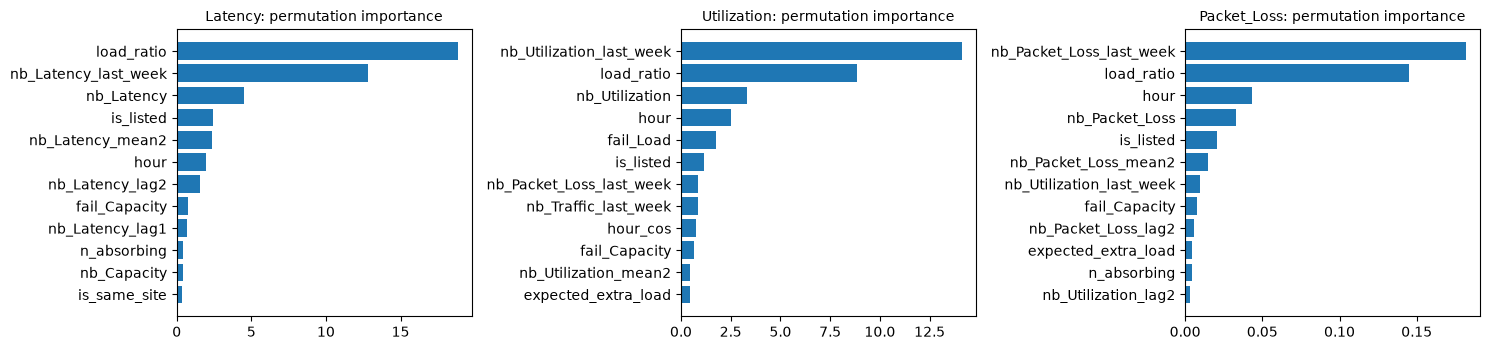

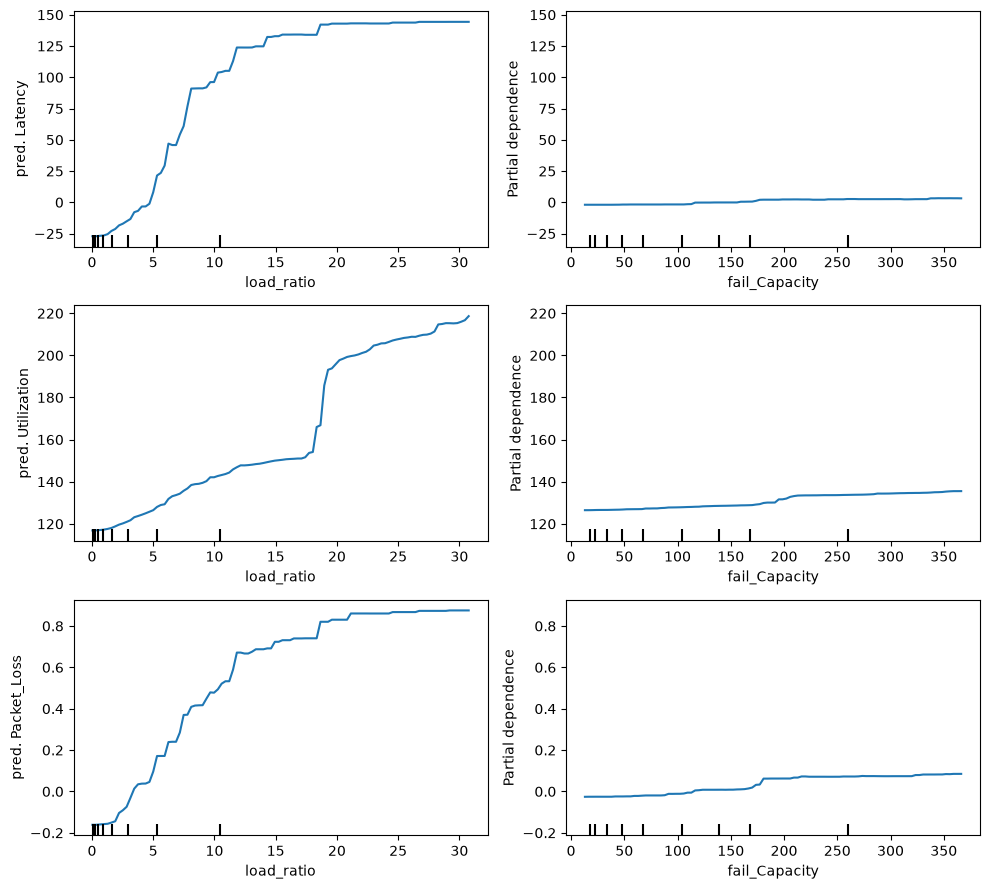

In [19]:
IMPORT = {}
for tgt in IMPACT_TARGETS:
    sel = BEST[tgt]["_best"]; m = BEST[tgt][sel]["model"]
    pi = permutation_importance(m, X["test"], SETS["test"][f"y_{tgt}"].to_numpy(float), n_repeats=5,
                                random_state=RANDOM_STATE, scoring="neg_mean_absolute_error", n_jobs=-1)
    IMPORT[tgt] = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
    IMPORT[tgt].to_csv(OUTPUT_DIR / f"importance_{tgt}.csv")
imp_tab = pd.DataFrame({t: IMPORT[t].head(12).index.tolist() for t in IMPACT_TARGETS})
print("Top 12 features per target (by increase in test MAE when shuffled)"); display(imp_tab)
group_of = {**{f: "neighbour current" for f in NB_CUR}, **{f: "neighbour lookback" for f in NB_LOOKBACK},
            **{f: "failed cell" for f in FAIL}, **{f: "load sharing" for f in SHARE},
            **{f: "last-week normal" for f in NORMAL}, **{f: "context" for f in CTX}}
print("Importance summed by feature group")
display(pd.DataFrame({t: IMPORT[t].clip(lower=0).groupby(group_of).sum() for t in IMPACT_TARGETS}).round(3))

fig, axes = plt.subplots(1, len(IMPACT_TARGETS), figsize=(5 * len(IMPACT_TARGETS), 3.6))
for ax, tgt in zip(np.atleast_1d(axes), IMPACT_TARGETS):
    imp_s = IMPORT[tgt].head(12)[::-1]; ax.barh(imp_s.index, imp_s.values); ax.set_title(f"{tgt}: permutation importance", fontsize=10)
plt.tight_layout(); plt.show()

share_feats = [f for f in IMPORT[IMPACT_TARGETS[0]].index if f in SHARE + FAIL][:2] or IMPORT[IMPACT_TARGETS[0]].index[:2].tolist()
sample = X["test"][np.random.default_rng(0).choice(len(X["test"]), min(2000, len(X["test"])), replace=False)]
fig, axes = plt.subplots(len(IMPACT_TARGETS), len(share_feats), figsize=(5 * len(share_feats), 3 * len(IMPACT_TARGETS)), squeeze=False)
for r_, tgt in enumerate(IMPACT_TARGETS):
    m = BEST[tgt][BEST[tgt]["_best"]]["model"]
    PartialDependenceDisplay.from_estimator(m, sample, [FEATURES.index(f) for f in share_feats], feature_names=FEATURES,
                                            ax=axes[r_], percentiles=(0.02, 0.98))
    axes[r_][0].set_ylabel(f"pred. {tgt}")
plt.tight_layout(); plt.show()

## 18. Operational views

* **Degraded-neighbour flag.** A neighbour is "degraded" if its KPI rises by more than `DEGRADED_REL_INCREASE` (20%) over its pre-outage value. The flag is derived from the regression predictions and scored against the actual outcome. The ranking score is predicted ÷ before.
* **Prediction intervals.** The 10th and 90th percentiles of validation residuals are added to each prediction, giving an 80% interval. Coverage is then checked on the test set and the unseen sites.

In [20]:
op, INTERVALS = [], {}
for tgt in IMPACT_TARGETS:
    sel = BEST[tgt]["_best"]
    res_v = SETS["valid"][f"y_{tgt}"].to_numpy(float) - PRED[tgt][sel]["valid"]
    q_lo, q_hi = np.percentile(res_v, [10, 90]); INTERVALS[tgt] = (float(q_lo), float(q_hi))
    for k in ["test", "unseen_june"]:
        if len(SETS[k]) == 0: continue
        y = SETS[k][f"y_{tgt}"].to_numpy(float); b = SETS[k][f"before_{tgt}"].to_numpy(float); p = PRED[tgt][sel][k]
        act = (y > b * (1 + DEGRADED_REL_INCREASE)).astype(int); prd = (p > b * (1 + DEGRADED_REL_INCREASE)).astype(int)
        score = p / np.where(b > 0, b, np.nan)
        ok = ~np.isnan(score)
        op.append({"Target": tgt, "Set": k, "degraded_rate_%": 100 * act.mean(),
                   "flag_precision": precision_score(act, prd, zero_division=0), "flag_recall": recall_score(act, prd, zero_division=0),
                   "flag_F1": f1_score(act, prd, zero_division=0),
                   "flag_ROC_AUC": roc_auc_score(act[ok], score[ok]) if 0 < act[ok].sum() < ok.sum() else np.nan,
                   "interval_80_coverage_%": 100 * np.mean((y >= p + q_lo) & (y <= p + q_hi)),
                   "interval_mean_width": q_hi - q_lo})
OP = pd.DataFrame(op); display(OP.round(3)); OP.to_csv(OUTPUT_DIR / "operational_views.csv", index=False)

,Target,Set,degraded_rate_%,flag_precision,flag_recall,flag_F1,flag_ROC_AUC,interval_80_coverage_%,interval_mean_width
0,Latency,test,39.911,0.722,0.769,0.745,0.860,79.328,48.582
1,Latency,unseen_june,42.384,0.739,0.785,0.761,0.853,78.201,48.582
2,Utilization,test,35.886,0.747,0.776,0.761,0.891,79.499,45.891
3,Utilization,unseen_june,39.625,0.755,0.753,0.754,0.885,77.815,45.891
4,Packet_Loss,test,44.278,0.745,0.812,0.777,0.868,79.754,0.768
5,Packet_Loss,unseen_june,48.951,0.795,0.804,0.799,0.872,80.629,0.768


### 18b. Warning threshold and comparison with the same-week rule

The deployed application uses Gradient Boosting for all three targets (section 19b), so the warning is evaluated with Gradient Boosting predictions. The analysis does two things:

* **Compares against a rule-based warning:** "warn if the neighbour's value at the same time last week was more than X% above its pre-outage value". This answers whether the model adds anything over the simplest warning an operator could build.
* **Tests stricter thresholds:** +10%, +20%, +30% and +50%. A stricter threshold flags fewer neighbours, so the warning becomes more selective.

Model vs same-week rule at +20% (split A test)


F1                                Precision                                  ROC_AUC                                   Recall               
Flag source Model (Gradient Boosting) Same-week rule Model (Gradient Boosting) Same-week rule Model (Gradient Boosting) Same-week rule Model (Gradient Boosting) Same-week rule
Target                                                                                                                                                                         
Latency                         0.745           0.31                     0.722          0.770                     0.860          0.717                     0.769          0.194
Packet_Loss                     0.777           0.44                     0.745          0.741                     0.868          0.730                     0.812          0.312
Utilization                     0.758           0.31                     0.747          0.695                     0.893          0.716                     0.769          0.200

Model warning at each threshold (split A test)


Truly_degraded_%                         Precision                          Recall                              F1                        
Target             Latency Utilization Packet_Loss   Latency Utilization Packet_Loss Latency Utilization Packet_Loss Latency Utilization Packet_Loss
Threshold                                                                                                                                           
+10%                54.682      50.827      55.364     0.745       0.789       0.774   0.845       0.826       0.854   0.792       0.807       0.812
+20%                39.911      35.886      44.278     0.722       0.747       0.745   0.769       0.769       0.812   0.745       0.758       0.777
+30%                30.275      26.028      35.937     0.717       0.745       0.732   0.746       0.769       0.788   0.731       0.757       0.759
+50%                20.501      17.295      26.676     0.750       0.759       0.722   0.746       0.772       0.767   0.748       0.765       0.744

Model warning on unseen sites, June


Precision                          Recall                              F1                        
Target      Latency Utilization Packet_Loss Latency Utilization Packet_Loss Latency Utilization Packet_Loss
Threshold                                                                                                  
+10%          0.761       0.808       0.807   0.833       0.831       0.841   0.795       0.820       0.824
+20%          0.739       0.750       0.795   0.785       0.763       0.804   0.761       0.756       0.799
+30%          0.732       0.778       0.766   0.755       0.755       0.794   0.743       0.766       0.780
+50%          0.764       0.769       0.748   0.686       0.736       0.805   0.723       0.753       0.776

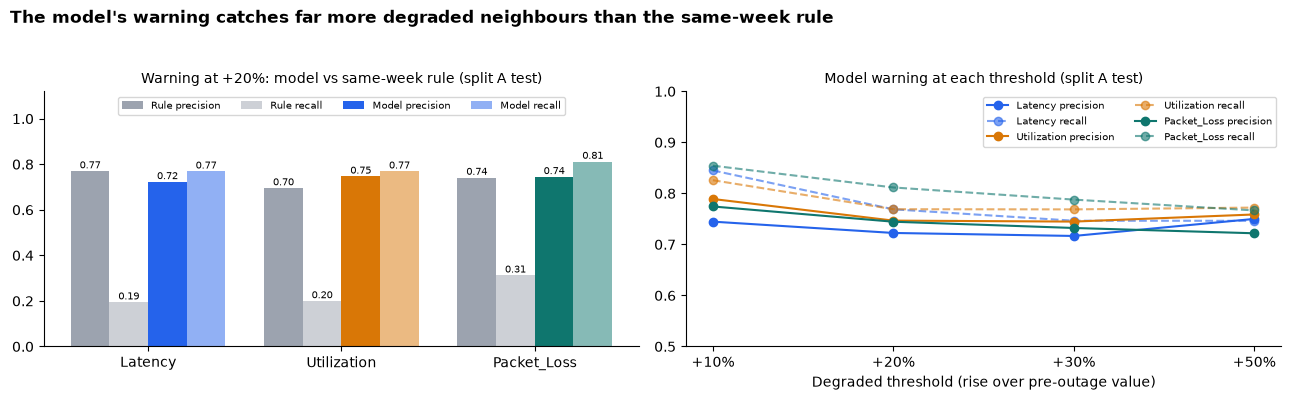

In [21]:
THRESHOLDS = [0.10, 0.20, 0.30, 0.50]
warn_rows = []
for tgt in IMPACT_TARGETS:
    for k in ["test", "unseen_june"]:
        if len(SETS[k]) == 0: continue
        y = SETS[k][f"y_{tgt}"].to_numpy(float); b = SETS[k][f"before_{tgt}"].to_numpy(float)
        p = PRED[tgt]["Gradient Boosting"][k]
        lw = SETS[k][f"nb_{tgt}_last_week"].to_numpy(float); lw = np.where(np.isnan(lw), b, lw)
        bb = np.where(b > 0, b, np.nan); ok = ~np.isnan(bb)
        for thr in THRESHOLDS:
            act = (y > b * (1 + thr)).astype(int)
            for src_name, pred_val in [("Model (Gradient Boosting)", p), ("Same-week rule", lw)]:
                flag = (pred_val > b * (1 + thr)).astype(int)
                score = pred_val / bb
                warn_rows.append({"Target": tgt, "Set": k, "Threshold": f"+{int(thr * 100)}%", "Flag source": src_name,
                                  "Truly_degraded_%": 100 * act.mean(), "Flagged_%": 100 * flag.mean(),
                                  "Precision": precision_score(act, flag, zero_division=0),
                                  "Recall": recall_score(act, flag, zero_division=0),
                                  "F1": f1_score(act, flag, zero_division=0),
                                  "ROC_AUC": roc_auc_score(act[ok], score[ok]) if 0 < act[ok].sum() < ok.sum() else np.nan})
WARN = pd.DataFrame(warn_rows)
WARN.to_csv(OUTPUT_DIR / "warning_threshold_comparison.csv", index=False)
print("Model vs same-week rule at +20% (split A test)")
display(WARN[(WARN.Threshold == "+20%") & (WARN.Set == "test")].pivot_table(
    index="Target", columns="Flag source", values=["Precision", "Recall", "F1", "ROC_AUC"]).round(3))
print("Model warning at each threshold (split A test)")
display(WARN[(WARN["Flag source"].str.startswith("Model")) & (WARN.Set == "test")].pivot_table(
    index="Threshold", columns="Target", values=["Truly_degraded_%", "Precision", "Recall", "F1"], sort=False).round(3))
print("Model warning on unseen sites, June")
display(WARN[(WARN["Flag source"].str.startswith("Model")) & (WARN.Set == "unseen_june")].pivot_table(
    index="Threshold", columns="Target", values=["Precision", "Recall", "F1"], sort=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
d20 = WARN[(WARN.Threshold == "+20%") & (WARN.Set == "test")]
x = np.arange(len(IMPACT_TARGETS)); w = 0.2
for j, (src_name, metric, alpha) in enumerate([("Same-week rule", "Precision", 1), ("Same-week rule", "Recall", 0.5),
                                               ("Model (Gradient Boosting)", "Precision", 1), ("Model (Gradient Boosting)", "Recall", 0.5)]):
    vals = [d20[(d20.Target == t) & (d20["Flag source"] == src_name)][metric].iloc[0] for t in IMPACT_TARGETS]
    cols = ["#9CA3AF"] * 3 if src_name.startswith("Same") else [KPI_COLOR[t] for t in IMPACT_TARGETS]
    bars = axes[0].bar(x + (j - 1.5) * w, vals, w, color=cols, alpha=alpha,
                       label=f"{'Rule' if src_name.startswith('Same') else 'Model'} {metric.lower()}")
    for bar_, v in zip(bars, vals):
        axes[0].annotate(f"{v:.2f}", (bar_.get_x() + bar_.get_width() / 2, v), xytext=(0, 2), textcoords="offset points",
                         ha="center", fontsize=7.5)
axes[0].set_xticks(x); axes[0].set_xticklabels(IMPACT_TARGETS); axes[0].set_ylim(0, 1.12)
axes[0].set_title("Warning at +20%: model vs same-week rule (split A test)", fontsize=10)
axes[0].legend(fontsize=7.5, ncol=4, loc="upper center"); axes[0].spines[["top", "right"]].set_visible(False)
dm = WARN[(WARN["Flag source"].str.startswith("Model")) & (WARN.Set == "test")]
for tgt in IMPACT_TARGETS:
    d = dm[dm.Target == tgt]
    axes[1].plot(d.Threshold, d.Precision, "o-", color=KPI_COLOR[tgt], label=f"{tgt} precision")
    axes[1].plot(d.Threshold, d.Recall, "o--", color=KPI_COLOR[tgt], alpha=0.6, label=f"{tgt} recall")
axes[1].set_ylim(0.5, 1); axes[1].set_xlabel("Degraded threshold (rise over pre-outage value)")
axes[1].set_title("Model warning at each threshold (split A test)", fontsize=10)
axes[1].legend(fontsize=7.5, ncol=2); axes[1].spines[["top", "right"]].set_visible(False)
plt.suptitle("The model's warning catches far more degraded neighbours than the same-week rule", x=0.01, ha="left",
             fontweight="bold", y=1.04)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig19_warning_comparison.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

## 19. Export for deployment

The bundle holds, for each target:
* the validation-selected model,
* the 80% interval offsets,
* the exact feature order,
* `impact_features()`, which builds the features from values a user can type in.

The check below rebuilds test rows from raw inputs through `impact_features()` and confirms they match the training features.

**App inputs, per neighbour:**
* The neighbour's 8 KPIs at its last observation before the outage, 3 h earlier and 6 h earlier.
* Its latency, utilization, packet loss, traffic and load at the same time last week (optional).
* The failed cell's traffic, users, load, capacity and throughput.
* The number of neighbours absorbing the load and their total capacity.
* The hour, whether the neighbour is on the same site and/or listed, and how many other site cells are already down.

In [22]:
import joblib

def impact_features(nb_now, nb_3h, nb_6h, failed, n_absorbing, total_absorbing_capacity, hour,
                    is_same_site, is_listed, site_cells_down=0, nb_last_week=None):
    """Build one feature row (dict keyed by FEATURES) from raw inputs, all from before the outage.
    nb_now, nb_3h, nb_6h: dicts with the 8 raw KPIs (RAW8) of the neighbour at its last observation, 3 h and 6 h earlier.
    failed: dict with Traffic, Connected_Users, Load, Capacity, Throughput of the failed cell.
    nb_last_week: optional dict with Latency, Utilization, Packet_Loss, Traffic, Load at the same slot last week."""
    def util(d):
        c = d.get("Capacity", np.nan)
        return 100 * d["Load"] / c if c and c > 0 else np.nan
    obs = [dict(d, Utilization=util(d)) for d in (nb_now, nb_3h, nb_6h)]
    f = {}
    for v in VARS9:
        cur, l1, l2 = (float(o.get(v, np.nan)) for o in obs)
        f[f"nb_{v}"] = cur; f[f"nb_{v}_lag1"] = l1; f[f"nb_{v}_lag2"] = l2
        f[f"nb_{v}_mean2"] = (l1 + l2) / 2; f[f"nb_{v}_trend2"] = cur - l2
    lwk = nb_last_week or {}
    for v in NORMAL_VARS: f[f"nb_{v}_last_week"] = float(lwk.get(v, np.nan))
    fl = dict(failed, Utilization=util(failed))
    for v in FAIL_VARS: f[f"fail_{v}"] = float(fl.get(v, np.nan))
    capn = obs[0]["Capacity"]
    share = capn / total_absorbing_capacity if total_absorbing_capacity > 0 else np.nan
    f.update({"n_absorbing": n_absorbing, "capacity_share": share, "expected_extra_load": f["fail_Load"] * share,
              "load_ratio": f["fail_Load"] / capn if capn > 0 else np.nan,
              "hour": hour, "hour_sin": np.sin(2 * np.pi * hour / 24), "hour_cos": np.cos(2 * np.pi * hour / 24),
              "is_same_site": int(is_same_site), "is_listed": int(is_listed), "site_cells_down": site_cells_down})
    return f

chk = SETS["test"].head(200) if len(SETS["test"]) else SETS["valid"].head(200)
max_diff = 0.0
for _, r in chk.iterrows():
    n, j, c = int(r.nbr_ci), int(r.se) - 1, int(r.fail_ci)
    raw = lambda jj: {v: float(G[v][n, jj]) for v in RAW8}
    nbrs = A_USE.indices[A_USE.indptr[c]:A_USE.indptr[c + 1]]
    ab = nbrs[has_kpi[nbrs, j] & ~down[nbrs, j]]
    f = impact_features(raw(j), raw(j - 1), raw(j - 2), {v: r[f"fail_{v}"] for v in FAIL_VARS if v != "Utilization"},
                        len(ab), float(np.nansum(G["Capacity"][ab, j])), int(r.hour), r.is_same_site, r.is_listed,
                        r.site_cells_down, {v: r[f"nb_{v}_last_week"] for v in NORMAL_VARS})
    a_ = np.array([f[k] for k in FEATURES], float); b_ = r[FEATURES].to_numpy(float)
    both = ~(np.isnan(a_) & np.isnan(b_))
    max_diff = max(max_diff, float(np.nanmax(np.abs(a_[both] - b_[both]) / (1 + np.abs(b_[both])))))
print(f"Feature rebuild check on {len(chk)} rows: max relative difference {max_diff:.2e}",
      "(OK)" if max_diff < 1e-4 else "(MISMATCH: check impact_features)")

bundle = {"targets": {}, "features": FEATURES, "raw_kpis": RAW8, "normal_vars": NORMAL_VARS, "fail_vars": FAIL_VARS,
          "lookback_steps": LOOKBACK_STEPS, "grid_step_h": GRID_STEP_H, "neighbour_source": NEIGHBOUR_SOURCE,
          "degraded_rel_increase": DEGRADED_REL_INCREASE, "train_period_end": str(TRAIN_END),
          "notes": "Predicts a neighbour's KPI at the first observation during another cell's outage. "
                   "All inputs must be from before the outage; build features with impact_features()."}
for tgt in IMPACT_TARGETS:
    sel = BEST[tgt]["_best"]
    bundle["targets"][tgt] = {"model": BEST[tgt][sel]["model"], "model_name": sel, "params": BEST[tgt][sel]["params"],
                              "interval_80": INTERVALS[tgt],
                              "test_metrics": RES[(RES.Target == tgt) & (RES.Model == sel) & (RES.Set == "test")]
                                              .drop(columns=["Target", "Model", "Set"]).to_dict("records")[0]}
joblib.dump(bundle, OUTPUT_DIR / "neighbour_impact_models.joblib")
print("Saved:", OUTPUT_DIR / "neighbour_impact_models.joblib")

Feature rebuild check on 200 rows: max relative difference 3.93e-06 (OK)
Saved: D:\AIT Aug26\ML\Project\Data\impact_outputs\neighbour_impact_models.joblib


### 19b. Deployment bundle: Gradient Boosting for all three targets

The report (Section 5.3) chose Gradient Boosting for every target. For utilization it is less than 1% less accurate than Random Forest, but it trains about 50 times faster, overfits less, makes a much smaller file and handles missing inputs natively.

This cell does five things:
* recomputes the 80% interval offsets from the Gradient Boosting validation residuals,
* overwrites `neighbour_impact_models.joblib` with the all-Gradient-Boosting bundle, after saving section 19's validation-selected bundle as `neighbour_impact_models_validation_selected.joblib`,
* records the Python and scikit-learn versions, because the deployment containers must use the same versions,
* writes `deploy_test_cases.json`: 25 test rows with their raw inputs, expected features and expected predictions. The app's automated tests check against these,
* reloads the bundle to confirm that it predicts.

In [23]:
import shutil, platform, sklearn
bundle_path = OUTPUT_DIR / "neighbour_impact_models.joblib"
if bundle_path.exists():
    shutil.copy(bundle_path, OUTPUT_DIR / "neighbour_impact_models_validation_selected.joblib")

DEPLOY_MODEL = "Gradient Boosting"
DEPLOY_INTERVALS, deploy_rows = {}, []
for tgt in IMPACT_TARGETS:
    gb = BEST[tgt][DEPLOY_MODEL]
    res_v = SETS["valid"][f"y_{tgt}"].to_numpy(float) - PRED[tgt][DEPLOY_MODEL]["valid"]
    q_lo, q_hi = np.percentile(res_v, [10, 90]); DEPLOY_INTERVALS[tgt] = (float(q_lo), float(q_hi))
    for k in ["test", "unseen_june"]:
        y = SETS[k][f"y_{tgt}"].to_numpy(float); b = SETS[k][f"before_{tgt}"].to_numpy(float); p = PRED[tgt][DEPLOY_MODEL][k]
        deploy_rows.append({"Target": tgt, "Set": k, **reg_metrics(y, p, b),
                            "Interval_80_coverage_%": 100 * np.mean((y >= p + q_lo) & (y <= p + q_hi)),
                            "Interval_width": q_hi - q_lo,
                            "Validation_selected_model": BEST[tgt]["_best"],
                            "Validation_selected_MAE": mean_absolute_error(y, PRED[tgt][BEST[tgt]["_best"]][k])})
DEPLOY = pd.DataFrame(deploy_rows); DEPLOY.to_csv(OUTPUT_DIR / "deployment_model_metrics.csv", index=False)
print("Deployed model (Gradient Boosting) vs validation-selected model")
display(DEPLOY.round(4))

bundle = {"targets": {}, "features": FEATURES, "raw_kpis": RAW8, "normal_vars": NORMAL_VARS, "fail_vars": FAIL_VARS,
          "vars9": VARS9, "lookback_steps": LOOKBACK_STEPS, "grid_step_h": GRID_STEP_H, "neighbour_source": NEIGHBOUR_SOURCE,
          "degraded_rel_increase": DEGRADED_REL_INCREASE, "train_period_end": str(TRAIN_END), "deploy_model": DEPLOY_MODEL,
          "python_version": platform.python_version(), "sklearn_version": sklearn.__version__,
          "numpy_version": np.__version__, "pandas_version": pd.__version__,
          "notes": "All three targets use Gradient Boosting. Predicts a neighbour's KPI at the first observation during "
                   "another cell's outage. All inputs must be from before the outage; build features with impact_features()."}
for tgt in IMPACT_TARGETS:
    t_ = DEPLOY[(DEPLOY.Target == tgt) & (DEPLOY.Set == "test")].iloc[0]
    bundle["targets"][tgt] = {"model": BEST[tgt][DEPLOY_MODEL]["model"], "model_name": DEPLOY_MODEL,
                              "params": BEST[tgt][DEPLOY_MODEL]["params"], "interval_80": DEPLOY_INTERVALS[tgt],
                              "test_metrics": {"MAE": t_.MAE, "R2_level": t_.R2_level, "R2_change": t_.R2_change}}
joblib.dump(bundle, bundle_path)
print(f"Saved {bundle_path} ({bundle_path.stat().st_size / 1e6:.1f} MB) | Python {bundle['python_version']}, "
      f"scikit-learn {bundle['sklearn_version']}, numpy {bundle['numpy_version']}")

# Test cases for the app: raw inputs exactly as a user would enter them, plus expected features and predictions
cases = []
chk = SETS["test"].sample(n=min(25, len(SETS["test"])), random_state=RANDOM_STATE)
for _, r in chk.iterrows():
    n, j, c = int(r.nbr_ci), int(r.se) - 1, int(r.fail_ci)
    raw = lambda jj: {v: float(G[v][n, jj]) for v in RAW8}
    nbrs = A_USE.indices[A_USE.indptr[c]:A_USE.indptr[c + 1]]
    ab = nbrs[has_kpi[nbrs, j] & ~down[nbrs, j]]
    inputs = {"nb_now": raw(j), "nb_3h": raw(j - 1), "nb_6h": raw(j - 2),
              "failed": {v: float(r[f"fail_{v}"]) for v in FAIL_VARS if v != "Utilization"},
              "n_absorbing": int(len(ab)), "total_absorbing_capacity": float(np.nansum(G["Capacity"][ab, j])),
              "hour": int(r.hour), "is_same_site": int(r.is_same_site), "is_listed": int(r.is_listed),
              "site_cells_down": int(r.site_cells_down),
              "nb_last_week": {v: float(r[f"nb_{v}_last_week"]) for v in NORMAL_VARS}}
    f = impact_features(**inputs)
    xrow = np.array([[f[k] for k in FEATURES]], np.float32)
    cases.append({"inputs": inputs, "expected_features": [None if np.isnan(v) else float(v) for v in xrow[0]],
                  "expected_predictions": {t: float(bundle["targets"][t]["model"].predict(xrow)[0]) for t in IMPACT_TARGETS},
                  "actual": {t: float(r[f"y_{t}"]) for t in IMPACT_TARGETS},
                  "before": {t: float(r[f"before_{t}"]) for t in IMPACT_TARGETS}})
def _clean(o):
    if isinstance(o, dict): return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, list): return [_clean(v) for v in o]
    return None if isinstance(o, float) and np.isnan(o) else o
(OUTPUT_DIR / "deploy_test_cases.json").write_text(json.dumps(_clean(cases), indent=1))
print(f"Saved {len(cases)} app test cases to {OUTPUT_DIR / 'deploy_test_cases.json'}")

loaded = joblib.load(bundle_path)
for tgt in IMPACT_TARGETS:
    same = np.allclose(loaded["targets"][tgt]["model"].predict(X["test"][:50]), PRED[tgt][DEPLOY_MODEL]["test"][:50])
    print(f"  {tgt}: reloaded bundle reproduces the notebook's predictions: {same}")

Deployed model (Gradient Boosting) vs validation-selected model


,Target,Set,MAE,RMSE,R2_level,R2_change,Interval_80_coverage_%,Interval_width,Validation_selected_model,Validation_selected_MAE
0,Latency,test,19.6890,38.4479,0.8143,0.7107,79.3280,48.5818,Gradient Boosting,19.6890
1,Latency,unseen_june,20.6531,40.3662,0.7932,0.6740,78.2009,48.5818,Gradient Boosting,20.6531
2,Utilization,test,18.2853,38.0625,0.7355,0.6827,79.7544,45.7744,Random Forest,18.1266
3,Utilization,unseen_june,20.1107,43.9601,0.6889,0.6220,78.1457,45.7744,Random Forest,19.4976
4,Packet_Loss,test,0.2493,0.3710,0.7649,0.6996,79.7544,0.7679,Gradient Boosting,0.2493
5,Packet_Loss,unseen_june,0.2550,0.3820,0.7565,0.6745,80.6291,0.7679,Gradient Boosting,0.2550


Saved D:\AIT Aug26\ML\Project\Data\impact_outputs\neighbour_impact_models.joblib (3.0 MB) | Python 3.13.15, scikit-learn 1.8.0, numpy 2.4.4
Saved 25 app test cases to D:\AIT Aug26\ML\Project\Data\impact_outputs\deploy_test_cases.json
  Latency: reloaded bundle reproduces the notebook's predictions: True
  Utilization: reloaded bundle reproduces the notebook's predictions: True
  Packet_Loss: reloaded bundle reproduces the notebook's predictions: True


## 20. Key observations

These sentences are generated from this run's numbers, so they always match the data. Check them before copying into the report.

In [24]:
obsv = []
s12 = signal_df.set_index("horizon_h")
obsv.append(f"Original target: a Random Forest predicting a new outage reaches lift "
            + ", ".join(f"{s12.loc[h, 'lift_over_random']:.2f}x ({h} h)" for h in s12.index)
            + f" over random in June; the largest |SMD| at any horizon is {signal_df['max_|SMD|'].max():.3f}, "
              "so KPIs carry little early warning of new outages.")
all_imp = did_summary(PAIRS[PAIRS.in_outage & (PAIRS.n_controls > 0)])
obsv.append("During outages, neighbours change by " + ", ".join(
    f"{v} {all_imp[f'{v}_%'].iloc[0]:+.1f}% (±{all_imp[f'{v}_CI±%'].iloc[0]:.1f})" for v in IMPACT_TARGETS)
    + " versus matched normal periods (difference-in-differences).")
bt = did_summary(PAIRS[PAIRS.in_outage & (PAIRS.n_controls > 0)], "nbr_type")
obsv.append("Impact by neighbour type (latency): " + ", ".join(f"{i}: {bt.loc[i, 'Latency_%']:+.1f}%" for i in bt.index) + ".")
dq_ = did_summary(D_ok, "load_ratio_q")
obsv.append(f"Dose-response: latency impact rises from {dq_['Latency_%'].iloc[0]:+.1f}% in the lowest to "
            f"{dq_['Latency_%'].iloc[-1]:+.1f}% in the highest quintile of failed load / neighbour capacity.")
post = did_summary(PAIRS[~PAIRS.in_outage & (PAIRS.n_controls > 0)])
obsv.append(f"Placebo-style check: when the observation falls after the outage has already ended, the latency change is "
            f"{post['Latency_%'].iloc[0]:+.1f}%, which supports the outage as the cause.")
for _, r in CI[CI.Set == "test"].iterrows():
    obsv.append(f"{r.Target}: {r.Model} has test MAE {r.MAE:.3f} (95% CI {r.MAE_CI}), "
                f"{r['MAE_reduction_%']:.1f}% lower than the best baseline ({r['Best baseline']}); "
                f"{'significant' if r.Significant else 'not significant'} by outage-level bootstrap.")
for tgt in IMPACT_TARGETS:
    sel = BEST[tgt]["_best"]
    t_ = RES[(RES.Target == tgt) & (RES.Model == sel)].set_index("Set")
    if "unseen_june" in t_.index:
        obsv.append(f"{tgt}: unseen-site June MAE {t_.loc['unseen_june', 'MAE']:.3f} vs development-site test "
                    f"{t_.loc['test', 'MAE']:.3f} (ratio {t_.loc['unseen_june', 'MAE'] / t_.loc['test', 'MAE']:.2f}); "
                    f"R² level {t_.loc['test', 'R2_level']:.2f}, R² change {t_.loc['test', 'R2_change']:.2f} on test.")
ab = ABL[ABL.Set == "test"].pivot_table(index="Feature set", columns="Target", values="MAE", sort=False)
obsv.append("Ablation (test MAE, latency): " + "; ".join(f"{i}: {ab.loc[i, IMPACT_TARGETS[0]]:.2f}" for i in ab.index) + ".")
obsv.append("Top 3 features: " + "; ".join(f"{t}: {', '.join(IMPORT[t].head(3).index)}" for t in IMPACT_TARGETS) + ".")
sh = pd.DataFrame(san).set_index("Target")["R2_test_shuffled_target"]
obsv.append("Shuffled-target R² on test: " + ", ".join(f"{t} {sh[t]:.3f}" for t in sh.index) + " (about 0 or below means no leakage).")
lcp = LC.pivot_table(index="train_fraction", columns="Target", values="test_MAE")
obsv.append("Learning curve (test MAE, 25% -> 100% of training outages): "
            + ", ".join(f"{t} {lcp[t].iloc[0]:.3f} -> {lcp[t].iloc[-1]:.3f}" for t in IMPACT_TARGETS) + ".")
for _, r in OP[OP.Set == "test"].iterrows():
    obsv.append(f"{r.Target}: degraded-neighbour flag precision {r.flag_precision:.2f}, recall {r.flag_recall:.2f} "
                f"(degraded rate {r['degraded_rate_%']:.1f}%); 80% interval covers {r['interval_80_coverage_%']:.1f}% of test cases.")
for i, s in enumerate(obsv, 1): print(f"{i}. {s}\n")
(OUTPUT_DIR / "key_observations.txt").write_text("\n".join(obsv), encoding="utf-8")

summary = {"cells": int(N_CELLS), "sites": int(len(SITES)), "outages": int(len(out)), "pairs": int(len(PAIRS)),
           "modelling_pairs": int(len(MD)), "neighbour_source": NEIGHBOUR_SOURCE,
           "set_sizes": {k: int(len(v)) for k, v in SETS.items()},
           "selected_models": {t: BEST[t]["_best"] for t in IMPACT_TARGETS},
           "results_with_ci": CI.to_dict("records"), "data_quality": dq, "random_state": RANDOM_STATE}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("All outputs saved under:", OUTPUT_DIR)

1. Original target: a Random Forest predicting a new outage reaches lift 1.14x (3 h), 1.12x (6 h), 1.03x (12 h) over random in June; the largest |SMD| at any horizon is 0.147, so KPIs carry little early warning of new outages.

2. During outages, neighbours change by Latency +38.8% (±1.3), Utilization +22.3% (±1.0), Packet_Loss +26.9% (±1.0) versus matched normal periods (difference-in-differences).

3. Impact by neighbour type (latency): other site, listed: +36.8%, same site, listed: +58.4%, same site, not listed: +10.0%.

4. Dose-response: latency impact rises from +6.6% in the lowest to +102.7% in the highest quintile of failed load / neighbour capacity.

5. Placebo-style check: when the observation falls after the outage has already ended, the latency change is -0.0%, which supports the outage as the cause.

6. Latency: Gradient Boosting has test MAE 19.689 (95% CI 18.429-21.070), 45.3% lower than the best baseline (Baseline: same slot last week); significant by outage-level bootst

### 20b. Key observations from the remaining work

In [25]:
more = []
ind = CV_DF[CV_DF.Note == ""]
more.append("Rolling CV (Gradient Boosting, independent folds " + ", ".join(ind.Fold.unique()) + "): MAE "
            + ", ".join(f"{t} {ind[ind.Target == t].MAE.min():.3g}-{ind[ind.Target == t].MAE.max():.3g}" for t in IMPACT_TARGETS)
            + "; error reduction vs the same-week rule "
            + ", ".join(f"{t} {ind[ind.Target == t]['Reduction_%'].min():.0f}-{ind[ind.Target == t]['Reduction_%'].max():.0f}%" for t in IMPACT_TARGETS)
            + "; R² (change) " + f"{ind.R2_change.min():.2f}-{ind.R2_change.max():.2f}.")
for tgt in IMPACT_TARGETS:
    s = TECH_REL[TECH_REL.Target == tgt].set_index("Technology")
    more.append(f"{tgt} by technology: error {s['Error_%_of_actual'].min():.0f}-{s['Error_%_of_actual'].max():.0f}% of the actual value "
                f"(highest {s['Error_%_of_actual'].idxmax()}, lowest {s['Error_%_of_actual'].idxmin()}); improvement over persistence "
                f"{s['Improvement_vs_persistence_%'].min():.0f}-{s['Improvement_vs_persistence_%'].max():.0f}%.")
w = WARN[(WARN.Set == "test") & (WARN.Threshold == "+20%")]
for tgt in IMPACT_TARGETS:
    mo = w[(w.Target == tgt) & w["Flag source"].str.startswith("Model")].iloc[0]
    ru = w[(w.Target == tgt) & (w["Flag source"] == "Same-week rule")].iloc[0]
    more.append(f"{tgt} warning at +20%: model precision {mo.Precision:.2f} / recall {mo.Recall:.2f} (F1 {mo.F1:.2f}) "
                f"vs same-week rule {ru.Precision:.2f} / {ru.Recall:.2f} (F1 {ru.F1:.2f}).")
w50 = WARN[(WARN.Set == "test") & (WARN.Threshold == "+50%") & WARN["Flag source"].str.startswith("Model")]
more.append("At +50%, the warning flags " + ", ".join(f"{r.Target} {r['Truly_degraded_%']:.0f}%" for _, r in w50.iterrows())
            + " of neighbours as truly degraded, with precision " + ", ".join(f"{r.Precision:.2f}" for _, r in w50.iterrows()) + ".")
for _, r in DEPLOY[DEPLOY.Set == "test"].iterrows():
    more.append(f"{r.Target}: deployed Gradient Boosting test MAE {r.MAE:.3f} vs validation-selected {r.Validation_selected_model} "
                f"{r.Validation_selected_MAE:.3f}; 80% interval coverage {r['Interval_80_coverage_%']:.1f}%.")
more.append(f"Bundle trained with Python {bundle['python_version']}, scikit-learn {bundle['sklearn_version']}: pin these in the containers.")
for i, s in enumerate(more, 1): print(f"{i}. {s}\n")
(OUTPUT_DIR / "key_observations_remaining_work.txt").write_text("\n".join(more), encoding="utf-8")

1. Rolling CV (Gradient Boosting, independent folds Jan-Feb -> Mar, Jan-Mar -> Apr, Jan-May -> Jun): MAE Latency 19.7-20.2, Utilization 18.1-18.9, Packet_Loss 0.244-0.251; error reduction vs the same-week rule Latency 42-45%, Utilization 36-38%, Packet_Loss 36-38%; R² (change) 0.67-0.72.

2. Latency by technology: error 9-21% of the actual value (highest 2G, lowest 5G); improvement over persistence 43-50%.

3. Utilization by technology: error 8-27% of the actual value (highest 2G, lowest 5G); improvement over persistence 47-57%.

4. Packet_Loss by technology: error 12-23% of the actual value (highest 2G, lowest 5G); improvement over persistence 44-49%.

5. Latency warning at +20%: model precision 0.72 / recall 0.77 (F1 0.74) vs same-week rule 0.77 / 0.19 (F1 0.31).

6. Utilization warning at +20%: model precision 0.75 / recall 0.77 (F1 0.76) vs same-week rule 0.70 / 0.20 (F1 0.31).

7. Packet_Loss warning at +20%: model precision 0.74 / recall 0.81 (F1 0.78) vs same-week rule 0.74 / 0.

1602